In [1]:
import os
import re
from datetime import datetime, timedelta
import pandas as pd
import numpy as np
from plotnine import *
from plotnine import ggplot, aes, theme_minimal, labs
from plotnine import geom_point, scale_size, scale_size_continuous
from plotnine import scale_x_discrete
from geopy.distance import geodesic
import geopandas as gpd
from shapely.geometry import Point, Polygon, MultiPolygon, LineString, MultiLineString
from scipy.stats import ttest_ind
from shapely.validation import make_valid

In [2]:
# This script allows me to plot data from the MCC continuous phylogeography tree
# The SERAPHIM plotting history script made an MCC CSV that I will be using

In [96]:
# Read in the MCC CSV

# FILE = "./SERAPHIM/nov2021-2024/NAm_wild-aves_nov2021-2024_ha_MCC.csv"
FILE = "./SERAPHIM/nov2021-2024_no-suliformes/NAm_wild-aves_nov2021-2024_no-suliformes_ha_MCC.csv"
# FILE = "./SERAPHIM/nov2021-2024_no-suliformes_contphyl-orderDTA/NAm_wild-aves_nov2021-2024_no-suliformes_contphyl-order_MCC.csv"

mcc = pd.read_csv(FILE, sep = ',')

In [97]:
mcc.head(7)

,node1,node2,length,startLon,startLat,endLon,endLat,endNodeL,startNodeL,startYear,endYear,tipLabel
0,5499,5500,0.152008,-75.083614,40.615106,-81.645311,37.979074,0.152008,0.000000,2021.600851,2021.752859,NaN
1,5500,6953,0.026361,-81.645311,37.979074,-81.438613,38.365291,0.178369,0.152008,2021.752859,2021.779220,NaN
2,5499,10834,0.202805,-75.083614,40.615106,-60.776378,45.982827,0.202805,0.000000,2021.600851,2021.803656,NaN
3,6953,6954,0.039270,-81.438613,38.365291,-80.033103,36.963447,0.217639,0.178369,2021.779220,2021.818490,NaN
4,6954,7662,0.001712,-80.033103,36.963447,-80.799196,37.288894,0.219351,0.217639,2021.818490,2021.820202,NaN
5,7662,10676,0.010405,-80.799196,37.288894,-82.899607,37.507120,0.229755,0.219351,2021.820202,2021.830606,NaN
6,7663,7664,-0.033456,-81.807028,37.749592,-88.561798,40.410044,0.252671,0.286126,2021.886977,2021.853522,NaN


In [73]:
# Compute the change in latitude between start and end nodes

mcc["changeLat"] = mcc["endLat"] - mcc["startLat"]

In [74]:
# Compute the change in longitude between start and end nodes

mcc["changeLon"] = mcc["endLon"] - mcc["startLon"]

In [75]:
# Add the whole starting and ending year

mcc["startYear_whole"] = mcc["startYear"].astype(str).str.split(".", expand=True)[0]
mcc["endYear_whole"] = mcc["endYear"].astype(str).str.split(".", expand=True)[0]

In [76]:
# I got the solstice and equinox dates from this website
# https://greenwichmeantime.com/longest-day/equinox-solstice-2021-2030/

In [77]:
# Compute the solstice and equinoxes in decimal format (developed by Chat GPT)

# List of date strings
date_strings = [
    "November 1 2021", "December 21 2021", "March 19 2022", "June 20 2022",
    "September 21 2022", "December 20 2022", "March 19 2023", "June 20 2023",
    "September 22 2023", "December 20 2023", "March 18 2024", "June 19 2024",
    "September 21 2024", "December 20 2024", "December 31 2024"
]

# Convert to datetime objects
dates = [datetime.strptime(date, "%B %d %Y") for date in date_strings]

# Function to convert date to decimal year
def to_decimal_year(date):
    year = date.year
    start_of_year = datetime(year, 1, 1)
    end_of_year = datetime(year + 1, 1, 1)
    year_length = (end_of_year - start_of_year).days
    day_of_year = (date - start_of_year).days
    return year + day_of_year / year_length

# Convert and print results
for date in dates:
    print(f"{date.strftime('%B %d %Y')}: {to_decimal_year(date):.5f}")

November 01 2021: 2021.83288
December 21 2021: 2021.96986
March 19 2022: 2022.21096
June 20 2022: 2022.46575
September 21 2022: 2022.72055
December 20 2022: 2022.96712
March 19 2023: 2023.21096
June 20 2023: 2023.46575
September 22 2023: 2023.72329
December 20 2023: 2023.96712
March 18 2024: 2024.21038
June 19 2024: 2024.46448
September 21 2024: 2024.72131
December 20 2024: 2024.96721
December 31 2024: 2024.99727


In [78]:
def seasons(df, column):
    df["year_rounded"] = df[column].round(5)

    def get_season(y):
        if y <= 2021.96986: # late autumn 2021
            return "autumn"
        elif 2021.96986 < y <= 2022.21096: # winter 2021-22
            return "winter"
        elif 2022.21096 < y <= 2022.46575: # spring 2022
            return "spring"
        elif 2022.46575 < y <= 2022.72055: # summer 2022
            return "summer"
        elif 2022.72055 < y <= 2022.96712: # autumn 2022
            return "autumn"
        elif 2022.96712 < y <= 2023.21096: # winter 2022-23
            return "winter"
        elif 2023.21096 < y <= 2023.46575: # spring 2023
            return "spring"
        elif 2023.46575 < y <= 2023.72329: # summer 2023
            return "summer"
        elif 2023.72329 < y <= 2023.96712: # autumn 2023
            return "autumn"
        elif 2023.96712 < y <= 2024.21038: # winter 2023-24
            return "winter"
        elif 2024.21038 < y <= 2024.46448: # spring 2024
            return "spring"
        elif 2024.46448 < y <= 2024.72131: # summer 2024
            return "summer"
        elif 2024.72131 < y <= 2024.96721: # autumn 2024
            return "autumn"
        elif y > 2024.96721: # winter 2024
            return "winter"
        else:
            return "unknown"

    df["season"] = df["year_rounded"].apply(get_season)
    return df.drop("year_rounded", axis=1)

In [79]:
def season_year(df, column):
    df["year_rounded"] = df[column].round(5)

    def get_season(y):
        if y <= 2021.96986: # late autumn 2021
            return "autumn_2021"
        elif 2021.96986 < y <= 2022.21096: # winter 2021-22
            return "winter_2021/22"
        elif 2022.21096 < y <= 2022.46575: # spring 2022
            return "spring_2022"
        elif 2022.46575 < y <= 2022.72055: # summer 2022
            return "summer_2022"
        elif 2022.72055 < y <= 2022.96712: # autumn 2022
            return "autumn_2022"
        elif 2022.96712 < y <= 2023.21096: # winter 2022-23
            return "winter_2022/23"
        elif 2023.21096 < y <= 2023.46575: # spring 2023
            return "spring_2023"
        elif 2023.46575 < y <= 2023.72329: # summer 2023
            return "summer_2023"
        elif 2023.72329 < y <= 2023.96712: # autumn 2023
            return "autumn_2023"
        elif 2023.96712 < y <= 2024.21038: # winter 2023-24
            return "winter_2023/24"
        elif 2024.21038 < y <= 2024.46448: # spring 2024
            return "spring_2024"
        elif 2024.46448 < y <= 2024.72131: # summer 2024
            return "summer_2024"
        elif 2024.72131 < y <= 2024.96721: # autumn 2024
            return "autumn_2024"
        elif y > 2024.96721: # winter 2024
            return "winter_2024"
        else:
            return "unknown"

    df["season_year"] = df["year_rounded"].apply(get_season)
    return df.drop("year_rounded", axis=1)

In [80]:
# Add seasons as per the end_year
mcc_seasons = seasons(mcc, "endYear")

# Also add season_year
mcc_seasons = season_year(mcc_seasons, "endYear")

In [81]:
def month(df, column):
    df["rounded"] = df[column].round(6)

    def get_month(y):
        if 2021.665753 <= y < 2021.747945: 
            return "september"
        elif 2021.747945 <= y < 2021.832877: 
            return "october"
        elif 2021.832877 <= y < 2021.915068: 
            return "november"
        elif 2021.915068 <= y < 2022.000000: 
            return "december"
        elif 2022.000000 <= y < 2022.084932: 
            return "january"
        elif 2022.084932 <= y < 2022.161644:
            return "february"
        elif 2022.161644 <= y < 2022.246575:
            return "march"
        elif 2022.246575 <= y < 2022.328767:
            return "april"
        elif 2022.328767 <= y < 2022.413699:
            return "may"
        elif 2022.413699 <= y < 2022.495890:
            return "june"
        elif 2022.495890 <= y < 2022.580822:
            return "july"
        elif 2022.580822 <= y < 2022.665753:
            return "august"
        elif 2022.665753 <= y < 2022.747945:
            return "september"
        elif 2022.747945 <= y < 2022.832877: 
            return "october"
        elif 2022.832877 <= y < 2022.915068:
            return "november"
        elif 2022.915068 <= y < 2023.000000:
            return "december"
        elif 2023.000000 <= y < 2023.084932:
            return "january"
        elif 2023.084932 <= y < 2023.161644:
            return "february"
        elif 2023.161644 <= y < 2023.246575:
            return "march"
        elif 2023.246575 <= y < 2023.328767:
            return "april"
        elif 2023.328767 <= y < 2023.413699:
            return "may"
        elif 2023.413699 <= y < 2023.495890:
            return "june"
        elif 2023.495890 <= y < 2023.580822:
            return "july"
        elif 2023.580822 <= y < 2023.665753:
            return "august"
        elif 2023.665753 <= y < 2023.747945:
            return "september"
        elif 2023.747945 <= y < 2023.832877:
            return "october"
        elif 2023.832877 <= y < 2023.915068:
            return "november"
        elif 2023.915068 <= y < 2024.000000:
            return "december"
        elif 2024.000000 <= y < 2024.084699:
            return "january"
        elif 2024.084699 <= y < 2024.163934:
            return "february"
        elif 2024.163934 <= y < 2024.248634:
            return "march"
        elif 2024.248634 <= y < 2024.330601:
            return "april"
        elif 2024.330601 <= y < 2024.415301:
            return "may"
        elif 2024.415301 <= y < 2024.497268:
            return "june"
        elif 2024.497268 <= y < 2024.581967:
            return "july"
        elif 2024.581967 <= y < 2024.666667:
            return "august"
        elif 2024.666667 <= y < 2024.748634:
            return "september"
        elif 2024.748634 <= y < 2024.833333:
            return "october"
        elif 2024.833333 <= y < 2024.915301:
            return "november"
        elif y >= 2024.915301:
            return "december"
        else:
            return "unknown"

    df["month"] = df["rounded"].apply(get_month)
    return df.drop("rounded", axis=1)

In [82]:
# Add month as per the endYear

mcc_seas_mon = month(mcc_seasons, "endYear")

In [83]:
# Add month_year column

mcc_seas_mon["month_year"] = mcc_seas_mon["endYear_whole"].astype(str) + "_" + mcc_seas_mon["month"].astype(str)

In [84]:
# Anna's distance function

# branch_data = []
# node_counter = 1  # for assigning unique names to internal nodes
# node_names = {}   # map object -> unique name

# for obj in ll.Objects:
#     # Assign a unique name to internal nodes if they don't have one
#     if not hasattr(obj, 'name') or obj.name is None:
#         if obj not in node_names:
#             node_names[obj] = f"node_{node_counter}"
#             node_counter += 1
#         obj_name = node_names[obj]
#     else:
#         obj_name = obj.name

#     # Assign a name to the parent node as well
#     parent = obj.parent
#     if parent:
#         if not hasattr(parent, 'name') or parent.name is None:
#             if parent not in node_names:
#                 node_names[parent] = f"node_{node_counter}"
#                 node_counter += 1
#             parent_name = node_names[parent]
#         else:
#             parent_name = parent.name

#         if 'location1' in obj.traits and 'location2' in obj.traits and \
#            'location1' in parent.traits and 'location2' in parent.traits:

#             child_coords = (obj.traits['location1'], obj.traits['location2'])
#             parent_coords = (parent.traits['location1'], parent.traits['location2'])

#             branch_data.append({
#                 'child_name': obj_name,
#                 'parent_name': parent_name,
#                 'child_type': obj.branchType,
#                 'parent_type': parent.branchType,
#                 'child_lat': child_coords[0],
#                 'child_long': child_coords[1],
#                 'parent_lat': parent_coords[0],
#                 'parent_long': parent_coords[1],
#                 'child_time': obj.absoluteTime if hasattr(obj, 'absoluteTime') else None,
#                 'parent_time': parent.absoluteTime if hasattr(parent, 'absoluteTime') else None,
#                 'distance_km': geodesic(child_coords, parent_coords, ellipsoid='GRS-80').kilometers
#             })

# branches_df = pd.DataFrame(branch_data)
# branches_df.head()

In [85]:
# Compute the distance between start and end nodes

def compute_distance(row):
    start = (row["startLat"], row["startLon"])
    end = (row["endLat"], row["endLon"])
    return geodesic(start, end, ellipsoid='GRS-80').kilometers

In [86]:
mcc_seas_mon["dist_km"] = mcc_seas_mon.apply(compute_distance, axis=1)

In [87]:
# Compute the time difference between start and end nodes

mcc_seas_mon["changeYear"] = mcc_seas_mon["endYear"] - mcc_seas_mon["startYear"]

In [94]:
print(mcc_seas_mon["changeYear"].min())
negative_time = mcc_seas_mon[mcc_seas_mon["changeYear"] < 0].loc[0:,["node1", "node2", "changeYear", "startYear", "endYear"]]
print(len(negative_time))
print(negative_time)

-0.07295643953011677
71
       node1  node2  changeYear    startYear      endYear
6       7663   7664   -0.033456  2021.886977  2021.853522
17      7581   7582   -0.022135  2021.917917  2021.895782
22      7871   7950   -0.004512  2021.913502  2021.908989
38     10765  10773   -0.000739  2021.917288  2021.916549
63      7653   7655   -0.008806  2021.951621  2021.942815
...      ...    ...         ...          ...          ...
10087   8617   8618   -0.000417  2023.637580  2023.637163
10095   9025   9026   -0.014634  2023.652542  2023.637908
10134   8933   8934   -0.001975  2023.681918  2023.679942
10349   8632   8633   -0.004937  2023.796903  2023.791966
10408   8990   8991   -0.002189  2023.814221  2023.812032

[71 rows x 5 columns]


In [20]:
# Compute speed (distance over time)

mcc_seas_mon["branchSpeed"] = mcc_seas_mon["dist_km"] / mcc_seas_mon["changeYear"]

In [21]:
# Function: assign a direction of movement to each branch

def change_direction(df):
    df_new = df.copy()
    
    df_new.loc[df_new["changeLat"] < 0, "changeLat_direction"] = "south"
    df_new.loc[df_new["changeLat"] > 0, "changeLat_direction"] = "north"
    df_new.loc[df_new["changeLat"] == 0, "changeLat_direction"] = "none"
    df_new.loc[df_new["changeLon"] < 0, "changeLon_direction"] = "west"
    df_new.loc[df_new["changeLon"] > 0, "changeLon_direction"] = "east"
    df_new.loc[df_new["changeLon"] == 0, "changeLon_direction"] = "none"

    return(df_new)

In [22]:
# Add columns for which branches are moving north, south, east, and west

mcc_seas_mon_withDirections = change_direction(mcc_seas_mon)

In [21]:
# Match lat/long to a flyway

In [25]:
# Anna's FIPS code assignment function

# def get_block_group_fips(lat, lon):
#     url = f"https://geo.fcc.gov/api/census/block/find?latitude={lat}&longitude={lon}&censusYear=2010&format=json"
#     response = requests.get(url)
#     data = response.json()
#     block_fips = data['Block']['FIPS']
#     block_group_fips = block_fips[:12]  # Truncate to 12 digits
#     return block_group_fips

# # Example
# print(get_block_group_fips(40.7128, -74.0060))  # Should return 12-digit FIPS

In [26]:
# First try by Clara

# from geopy.geocoders import Nominatim

# geolocator = Nominatim(user_agent="cm_plotting_app")

# def state(df, column1, column2):
#     coords = str((df[column1], df[column2]))
#     location = geolocator.reverse(coords)
#     state = location.raw["address"].get("state")
#     return state

In [27]:
# Second try by Chat GPT - too slow!

# Set up geolocator globally
# geolocator = Nominatim(user_agent="geo_lookup_app")

# def reverse_geocode(lat, lon):
#     try:
#         location = geolocator.reverse((lat, lon), language='en')
#         if location and 'state' in location.raw['address']:
#             return location.raw['address']['state']
#         else:
#             return None
#     except GeocoderTimedOut:
#         time.sleep(1)
#         return reverse_geocode(lat, lon)  # Retry once
#     except Exception as e:
#         print(f"Error for ({lat}, {lon}): {e}")
#         return None

# def add_state_column(df, lat_col, lon_col):
#     df["state"] = df.apply(lambda row: reverse_geocode(row[lat_col], row[lon_col]), axis=1)
#     return df

In [23]:
# Need a shapefile to dictate polygon boundaries

# North America shapefile
NAm_shp_path = "./metadata/shapefiles/north_america/north_america.shp"
NAm_gdf = gpd.read_file(NAm_shp_path)

# Downloaded US shapefile from Natural Earth
# Downloaded Canadian province shapefile from: https://open.canada.ca/data/en/dataset/a883eb14-0c0e-45c4-b8c4-b54c4a819edb/resource/12c03de6-c3f7-4f5f-bb5c-d479f2332842
# Downloaded Mexican state shapefile from: https://github.com/jschleuss/mexican-states

In [24]:
# I would like to see what is happening in my shapefile DF

NAm_gdf["geometry_name"] = NAm_gdf["name"].combine_first(NAm_gdf["PRNAME"])
columns = ["geometry", "geometry_name", "place", "type", "latitude", "longitude", "fips", "region", "gadm_level"]
NAm_gdf = NAm_gdf.loc[0:, columns]

NAm_gdf = NAm_gdf.to_crs("EPSG:4326")

In [30]:
NAm_gdf_validated = NAm_gdf.copy()
NAm_gdf_validated["geometry"] = NAm_gdf_validated["geometry"].apply(make_valid)

# This takes a little while

In [25]:
print(NAm_gdf_validated[~NAm_gdf_validated.is_valid])

NameError: name 'NAm_gdf_validated' is not defined

In [26]:
# Create geometries for each start and end point in the MCC tree

mcc_seas_mon_withDirections['startGeometry'] = mcc_seas_mon_withDirections.apply(lambda row: Point(row['startLon'], row['startLat']), axis=1)
mcc_seas_mon_withDirections['endGeometry'] = mcc_seas_mon_withDirections.apply(lambda row: Point(row['endLon'], row['endLat']), axis=1)

geop_mcc_seas_mon_withDirections_start = gpd.GeoDataFrame(mcc_seas_mon_withDirections, geometry='startGeometry', crs="EPSG:4326")
geop_mcc_seas_mon_withDirections_end = gpd.GeoDataFrame(mcc_seas_mon_withDirections, geometry='endGeometry', crs="EPSG:4326")

geop_mcc_seas_mon_withDirections_start = geop_mcc_seas_mon_withDirections_start.set_crs("EPSG:4326", allow_override=True)
geop_mcc_seas_mon_withDirections_end = geop_mcc_seas_mon_withDirections_end.set_crs("EPSG:4326", allow_override=True)

# print(geop_mcc_seas_mon_withDirections_start)

In [27]:
# Function: use gpd.sjoin to assign coordinates to the state (made by Chat GPT)

def assign_state(df, geom_col, states_gdf, new_col):
    temp = df.set_geometry(geom_col, inplace=False)

    # CRS check and force match
    if temp.crs != states_gdf.crs:
        temp = temp.to_crs(states_gdf.crs)

    result = gpd.sjoin(temp, states_gdf[["geometry_name", "geometry"]], how="left", predicate="within")
    
    result_renamed = result.rename(columns={"geometry_name": new_col})
    
    # Detect duplicated indices (geometries within multiple states)
    duplicate_indices = result_renamed.index[result_renamed.index.duplicated(keep=False)]

    # Assign 'unknown' to all duplicated rows
    result_renamed.loc[duplicate_indices, new_col] = "unknown"

    # Drop all but the first instance of each original index
    deduped = result_renamed[~result_renamed.index.duplicated(keep='first')]

    # Build final series and align with original df
    state_series = deduped[new_col]
    
    # return print(result_renamed[result_renamed.index.isin(duplicate_indices)])
    return state_series.reindex(df.index)

In [28]:
mcc_seas_mon_withDirections["startState"] = assign_state(geop_mcc_seas_mon_withDirections_start, "startGeometry", NAm_gdf, "startState")
# Indexes 3144 and 3294 have two start states?
mcc_seas_mon_withDirections["endState"] = assign_state(geop_mcc_seas_mon_withDirections_end, "endGeometry", NAm_gdf, "endState")
# Index 2086 has two end states?

In [29]:
# Fix state/province names

# No French! (also some Mexico changes)
no_french_dict = {"Newfoundland and Labrador / Terre-Neuve-et-Labrador":"Newfoundland",
                 "Prince Edward Island / Île-du-Prince-Édouard":"Prince Edward Island",
                 "British Columbia / Colombie-Britannique":"British Columbia",
                 "Northwest Territories / Territoires du Nord-Ouest":"Northwest Territories",
                 "Quebec / Québec":"Quebec",
                 "Nova Scotia / Nouvelle-Écosse":"Nova Scotia",
                 "New Brunswick / Nouveau-Brunswick":"New Brunswick",
                 "Coahuila de Zaragoza":"Coahuila",
                 "Veracruz de Ignacio de la Llave":"Veracruz",
                 "Michoacán de Ocampo":"Michoacán"
                 }

# Make the above adjustments (if 
mcc_seas_mon_withDirections["startState"] = mcc_seas_mon_withDirections["startState"].map(no_french_dict).fillna(mcc_seas_mon_withDirections["startState"]) 
mcc_seas_mon_withDirections["endState"] = mcc_seas_mon_withDirections["endState"].map(no_french_dict).fillna(mcc_seas_mon_withDirections["endState"])

In [30]:
# Function: Standardize state names

def fix_state_name(name):
    if pd.isna(name):
        return name
    replacements = {"é": "e", "á": "a", "í": "i", "ó": "o"}
    name = name.lower()
    name = name.replace("-", "").replace(" ", "").replace("'", "")
    for accented, plain in replacements.items():
        name = name.replace(accented, plain)
    return name

In [31]:
# Standardize the states in both startState and endState

mcc_seas_mon_state = mcc_seas_mon_withDirections.copy()

mcc_seas_mon_state["startState"] = mcc_seas_mon_state["startState"].apply(fix_state_name)
mcc_seas_mon_state["endState"] = mcc_seas_mon_state["endState"].apply(fix_state_name)

In [32]:
# Upload the state and flyway and turn it into a dictionary

# Upload the CSV of the state and flyway
state_flyway_csv = "./metadata/helpful_lists/flywayregions_biggerlist.csv"

state_flyway_df = pd.read_csv(state_flyway_csv, sep = ',') 

# Turn this CSV into a dictionary
state_flyway_dict = state_flyway_df.set_index("location").to_dict(orient="index")

In [33]:
# Add flyway

mcc_seas_mon_state_flyway = mcc_seas_mon_state.copy()

mcc_seas_mon_state_flyway["startFlyway"] = mcc_seas_mon_state_flyway["startState"].map(lambda state: state_flyway_dict.get(state, {}).get("flyway"))
mcc_seas_mon_state_flyway["endFlyway"] = mcc_seas_mon_state_flyway["endState"].map(lambda state: state_flyway_dict.get(state, {}).get("flyway"))

In [34]:
# I wanted to check if either column has "unknown" values

print(mcc_seas_mon_state_flyway["startFlyway"].value_counts())
print(mcc_seas_mon_state_flyway["endFlyway"].value_counts())

# Both do have unknowns, probably because those coordinates are in the ocean

startFlyway
CentralFlyway        3180
MississippiFlyway    2712
AtlanticFlyway       2582
PacificFlyway        2146
unknown               374
Name: count, dtype: int64
endFlyway
CentralFlyway        2856
MississippiFlyway    2810
AtlanticFlyway       2773
PacificFlyway        2308
unknown               246
Name: count, dtype: int64


In [35]:
# Create a DataFrame of lat/lon from the geometries
def geom_to_df(geom, region_name):
#     if isinstance(geom, Polygon):
#         coords = list(geom.exterior.coords)
#         df = pd.DataFrame(coords, columns=['lon', 'lat'])
#         df['region'] = region_name
#         df['group'] = f"{region_name}_0"
#         return df

#     elif isinstance(geom, MultiPolygon):
#         dfs = []
#         for i, part in enumerate(geom.geoms):
#             coords = list(part.exterior.coords)
#             df = pd.DataFrame(coords, columns=['lon', 'lat'])
#             df['region'] = region_name
#             df['group'] = f"{region_name}_{i}"
#             dfs.append(df)
#             # Add NaN to separate parts (important for line-based plotting)
            # dfs.append(pd.DataFrame({
            #     'lon': [np.nan],
            #     'lat': [np.nan],
            #     'region': [region_name],
            #     'group': [f"{region_name}_{i}"]
            # }))
#         return pd.concat(dfs, ignore_index=True)

    if isinstance(geom, LineString):
        coords = list(geom.coords)
        df = pd.DataFrame(coords, columns=['lon', 'lat'])
        df['region'] = region_name
        df['group'] = f"{region_name}_0"
        return df

    elif isinstance(geom, MultiLineString):
        dfs = []
        for i, part in enumerate(geom.geoms):
            coords = list(part.coords)
            df = pd.DataFrame(coords, columns=['lon', 'lat'])
            df['region'] = region_name
            df['group'] = f"{region_name}_{i}"
            dfs.append(df)
#            dfs.append(pd.DataFrame({'lon': [np.nan],'lat': [np.nan],'region': [region_name],'group': [f"{region_name}_{i}"]}))
        return pd.concat(dfs, ignore_index=True)

    else:
        return pd.DataFrame(columns=['lon', 'lat', 'region', 'group'])

In [36]:
# I suspect all the unknowns are either in the Atlantic or Pacific Ocean, but I will need to be sure

# subset dataframe to just those with unknown start flyway
unknown_starts = mcc_seas_mon_state_flyway[mcc_seas_mon_state_flyway["startFlyway"] == "unknown"]
unknown_ends = mcc_seas_mon_state_flyway[mcc_seas_mon_state_flyway["endFlyway"] == "unknown"]

# Maybe plot these? Or set a boundary and see if they're beyond it
COASTLINES = "./metadata/shapefiles/ne_10m_coastline/ne_10m_coastline.shp"
coastlines_gdf = gpd.read_file(COASTLINES)
coastlines_gdf = coastlines_gdf.to_crs("EPSG:4326")

# Optional cleaning
coastlines_gdf = coastlines_gdf[coastlines_gdf.is_valid]
coastlines_gdf = coastlines_gdf[~coastlines_gdf.geometry.is_empty]

map_df = pd.concat([geom_to_df(row.geometry, row['featurecla']) for idx, row in coastlines_gdf.iterrows()], ignore_index=True)
filtered_map_df = map_df[
    (map_df['lat'] >= 0) & (map_df['lat'] <= 80) &
    (map_df['lon'] >= -180) & (map_df['lon'] <= -30)
]

starts = (
    ggplot(filtered_map_df) +
    geom_path(aes(x='lon', y='lat', group='group'), color='gray') +
    geom_point(data=unknown_starts, mapping=aes(x='startLon', y='startLat'), color='blue', alpha=0.6) +
    coord_fixed() +
    theme_minimal() +
    theme(figure_size=(7, 5)) +
    labs(title='Unknown Starts')
)
#starts.show()

ends = (
    ggplot(map_df) +
    geom_path(aes(x='lon', y='lat', group='group'), color='gray') +
    geom_point(data=unknown_ends, mapping=aes(x='endLon', y='endLat'), color='red', alpha=0.6) +
    coord_fixed() +
    theme_minimal() +
    theme(figure_size=(7, 5)) +
    labs(title='Unknown Ends')
)
#ends.show()

In [37]:
# After checking with Louise, the plan is to cluster unknown starts and ends and set them into a flyway

def set_unknown_points(df, column1, column2, column3):

    df_new = df.copy()

    unknown = df_new[column1] == "unknown"
    lat = df_new[column2]
    long = df_new[column3]

    # Conditions for assigning flyways
    cond1 = (unknown) & (lat < 20) # If latitude < 20, then Central Flyway
    cond2 = (unknown) & (lat > 20) & (long > -85) # If latitude > 20 and longitude > -85, then Atlantic Flyway
    cond3 = (unknown) & (lat > 20) & (long.between(-94, -85)) # If latitude > 20 and -94 ≤ longitude < -85, then Mississippi Flyway
    cond4 = (unknown) & (lat > 20) & (long.between(-110, -94)) # If latitude > 20 and -110 ≤ longitude < -94, then Central Flyway
    cond5 = (unknown) & (lat > 20) & (long < -110) # If latitude > 20 and longitude < -110, then Pacific Flyway

    # Assign new values based on conditions
    df_new.loc[cond1, column1] = "CentralFlyway"
    df_new.loc[cond2, column1] = "AtlanticFlyway"
    df_new.loc[cond3, column1] = "MississippiFlyway"
    df_new.loc[cond4, column1] = "CentralFlyway"
    df_new.loc[cond5, column1] = "PacificFlyway"

    return(df_new)

In [38]:
# Update the unknown start and end flyways

mcc_seas_mon_state_flyway_upt1 = set_unknown_points(mcc_seas_mon_state_flyway, "startFlyway", "startLat", "startLon")
mcc_seas_mon_state_flyway_upt2 = set_unknown_points(mcc_seas_mon_state_flyway_upt1, "endFlyway", "endLat", "endLon")

In [39]:
# Add a column if the start flyway and end flyway are different

# Initialize the column with default value
mcc_seas_mon_state_flyway_upt2["changeFlyway"] = "yes"

# Assign 'yes' where start == end
mcc_seas_mon_state_flyway_upt2.loc[mcc_seas_mon_state_flyway_upt2["startFlyway"] == mcc_seas_mon_state_flyway_upt2["endFlyway"], "changeFlyway"] = "no"

In [40]:
# Add a column if start host order and end host order are different

# Initialize the column with default value
mcc_seas_mon_state_flyway_upt2["changeOrder"] = "yes"

# Assign 'yes' where start == end
mcc_seas_mon_state_flyway_upt2.loc[mcc_seas_mon_state_flyway_upt2["startOrder"] == mcc_seas_mon_state_flyway_upt2["endOrder"], "changeOrder"] = "no"

In [57]:
# Print this updated MCC CSV

#mcc_seas_mon_state_flyway_upt2.to_csv("./SERAPHIM/nov2021-2024/NAm_wild-aves_nov2021-2024_ha_MCC_updated.csv", sep = ',')
# mcc_seas_mon_state_flyway_upt2.to_csv("./SERAPHIM/nov2021-2024_no-suliformes/NAm_wild-aves_nov2021-2024_no-suliformes_ha_MCC_updated.csv", sep = ',')
mcc_seas_mon_state_flyway_upt2.to_csv("./SERAPHIM/nov2021-2024_no-suliformes_contphyl-orderDTA/NAm_wild-aves_nov2021-2024_no-suliformes_contphyl-order_MCC_updated.csv", sep = ',')

In [39]:
# Optional: subset the mcc CSV to branches traveling a certain distance

mcc_over100km = mcc_seas_mon_state_flyway_upt2[mcc_seas_mon_state_flyway_upt2["dist_km"] > 100]
mcc_over200km = mcc_seas_mon_state_flyway_upt2[mcc_seas_mon_state_flyway_upt2["dist_km"] > 200]
mcc_over300km = mcc_seas_mon_state_flyway_upt2[mcc_seas_mon_state_flyway_upt2["dist_km"] > 300]
mcc_over500km = mcc_seas_mon_state_flyway_upt2[mcc_seas_mon_state_flyway_upt2["dist_km"] > 500]

In [40]:
# GOTTA CHANGE ALL THE DATAFRAMES FROM HERE DOWN!!!!!!

In [42]:
# Set the dataframe for all plotting and statistics

MCCDATA = mcc_seas_mon_state_flyway_upt2
#MCCDATA = mcc_over100km
#MCCDATA = mcc_over200km
#MCCDATA = mcc_over300km
#MCCDATA = mcc_over500km

print(len(MCCDATA))

10994


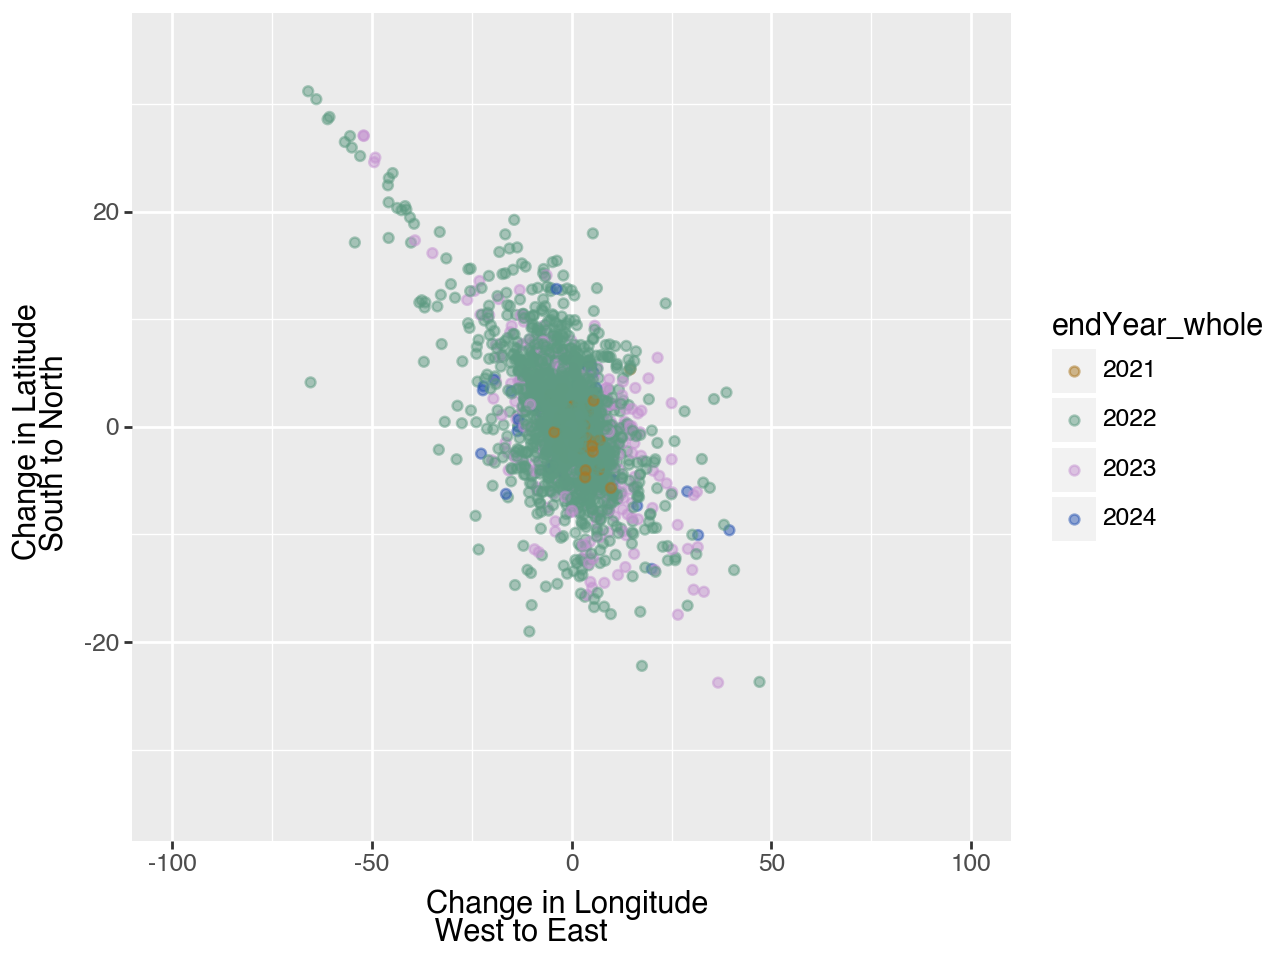

In [42]:
# Plot 1: change in direction of all points

year_colors = {"2021":"#AA7722",
               "2022":"#5E9B82",
               "2023":"#C593D1",
               "2024":"#2B57B3"
              }

years = ["2021",
        "2022",
        "2023"
        ]

MCCDATA_filtered = MCCDATA[MCCDATA["endYear_whole"].isin(years)]

all_time_scatter = (
    ggplot(MCCDATA, 
           aes(x = "changeLon", y = "changeLat", color = "endYear_whole")) 
    + geom_point(alpha = 0.5)
#    + stat_ellipse(type='t', level=0.95, linetype='dashed', size=1)
    + scale_color_manual(values=year_colors)
    + xlim(-100, 100)
    + ylim(-35, 35)
    + labs(x = "Change in Longitude \n West to East", y = "Change in Latitude \n South to North")
)

all_time_scatter.show()

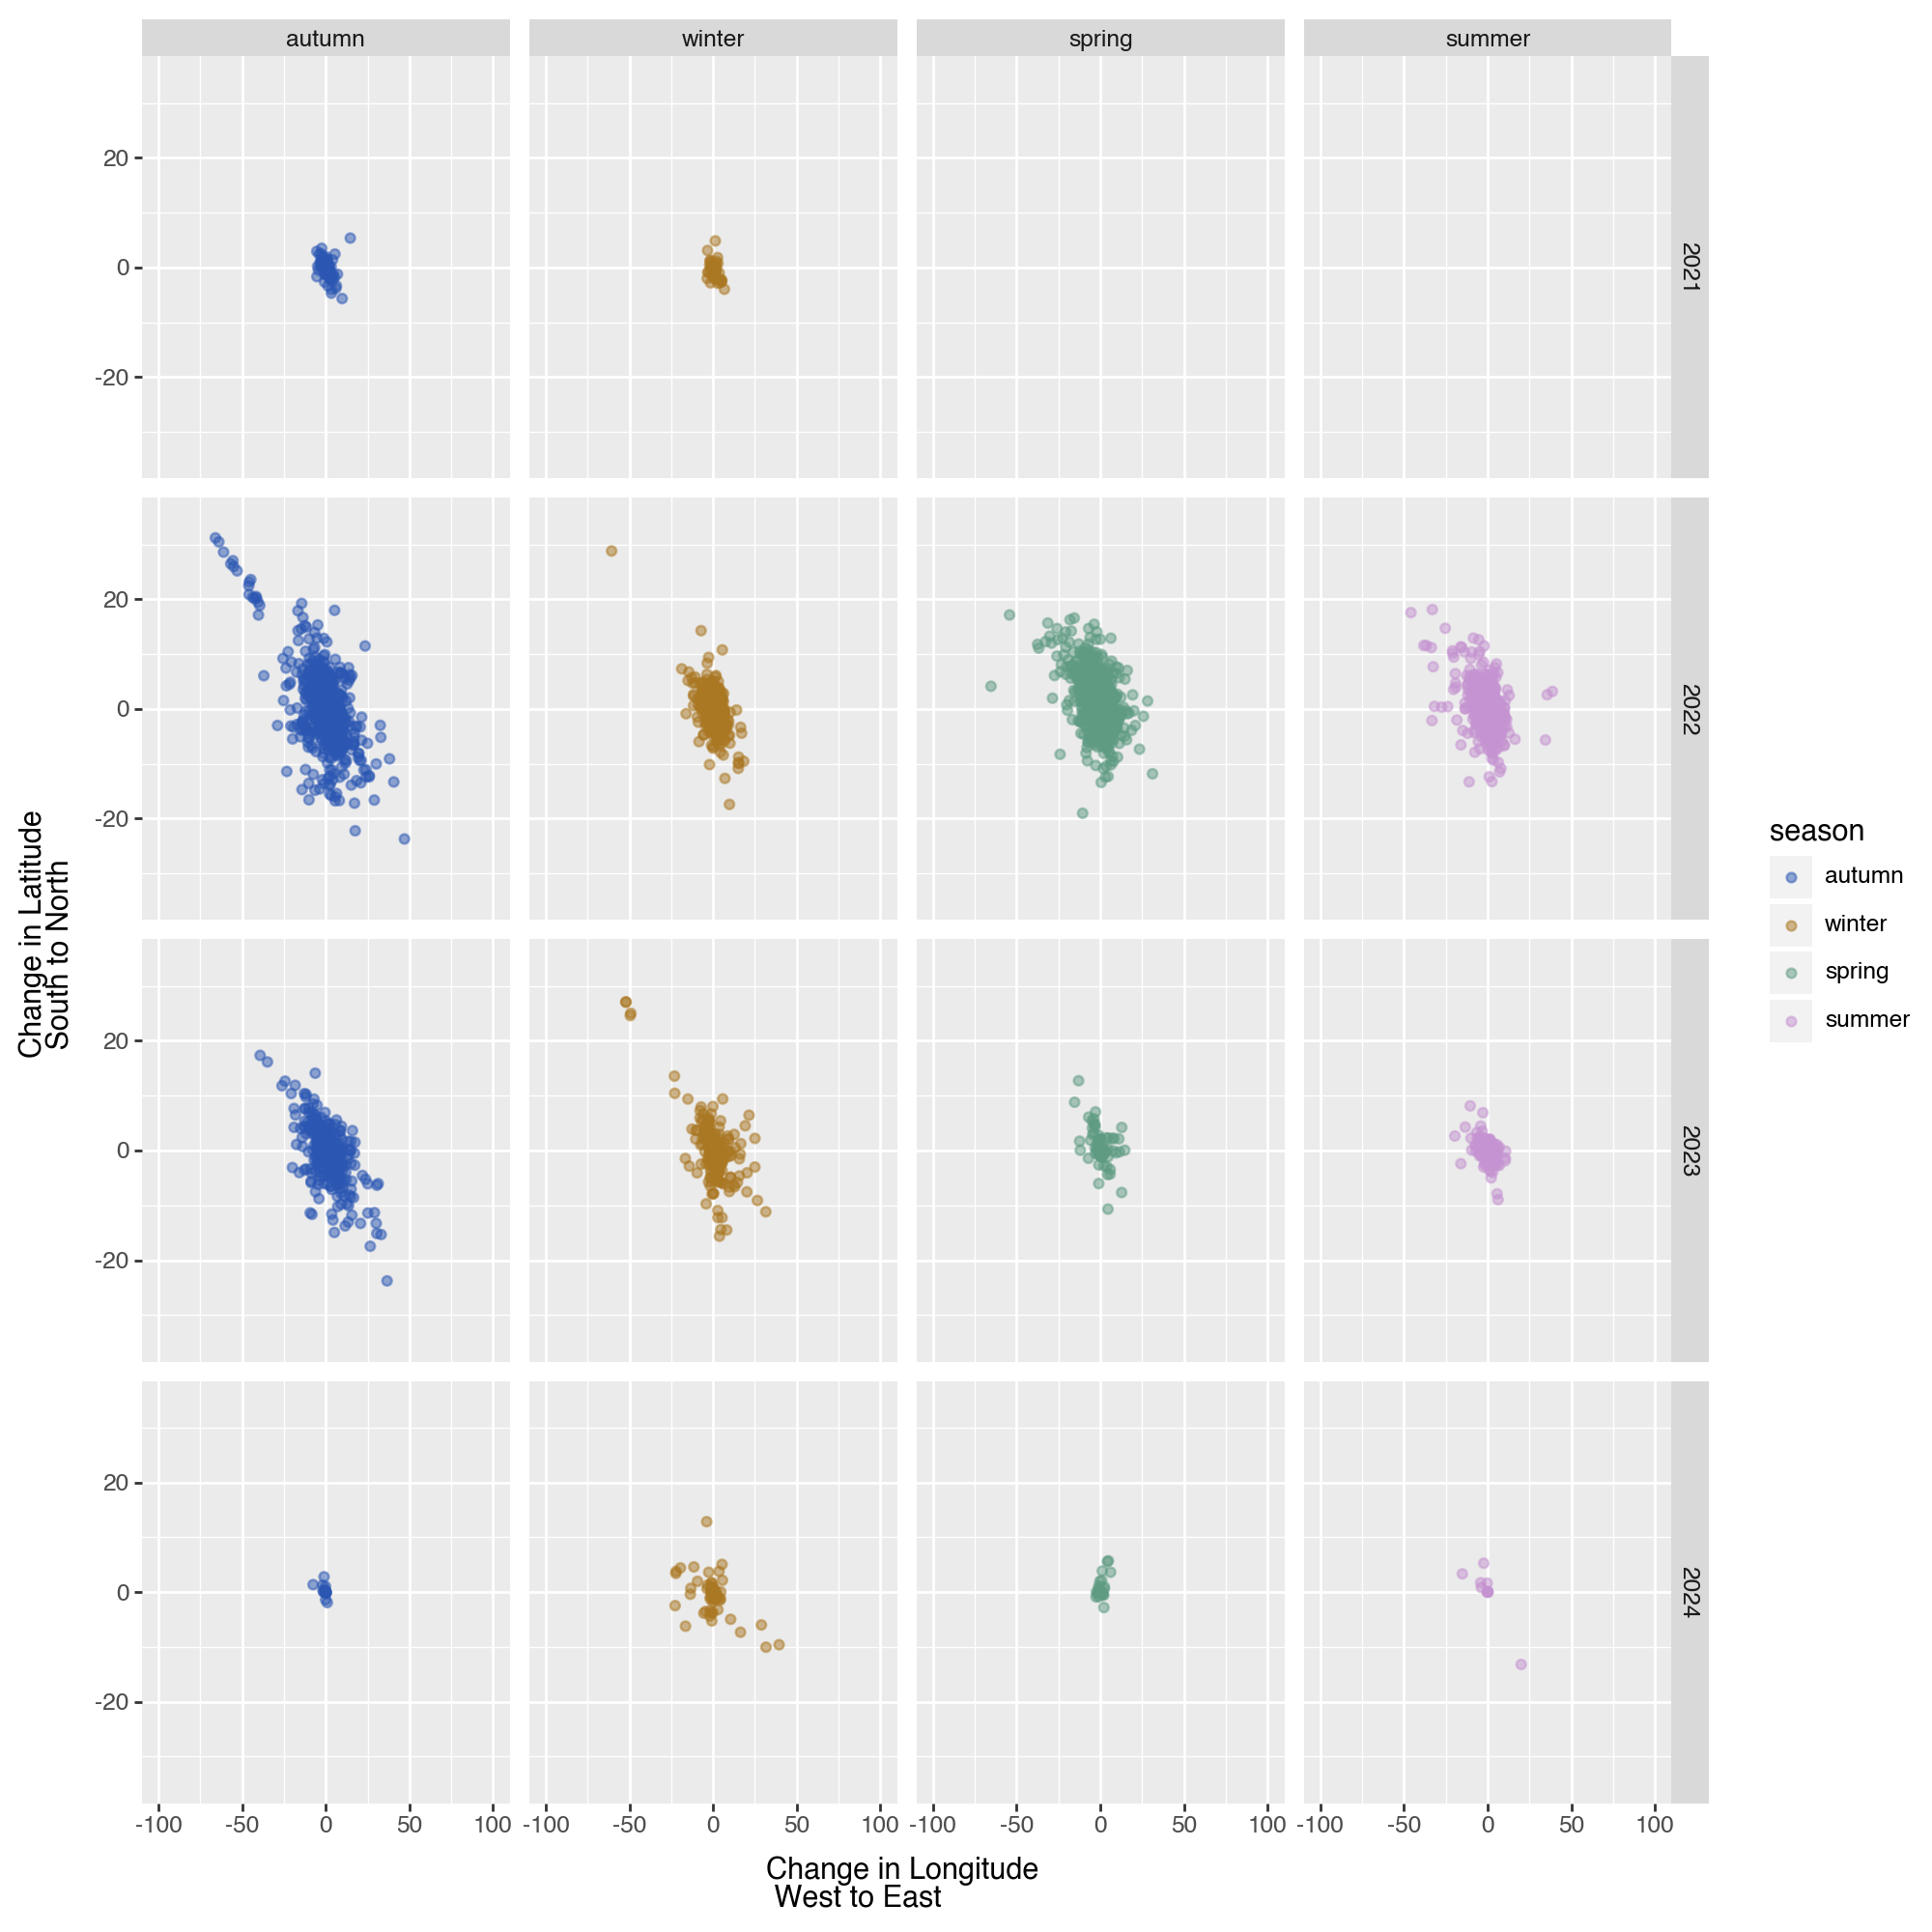

/Users/claramal/miniconda3/lib/python3.11/site-packages/plotnine/ggplot.py:606: PlotnineWarning: Saving 10 x 7 in image.
/Users/claramal/miniconda3/lib/python3.11/site-packages/plotnine/ggplot.py:607: PlotnineWarning: Filename: ./SERAPHIM/nov2021-2024_no-suliformes_contphyl-orderDTA//output_plots/seasonal_scatter.pdf


In [44]:
# Plot 1.5: change in direction, colored by season, facetted by year

season_colors = {"winter":"#AA7722",
               "spring":"#5E9B82",
               "summer":"#C593D1",
               "autumn":"#2B57B3"
              }

season_order = ["autumn", "winter", "spring", "summer"]
MCCDATA["season"] = pd.Categorical(MCCDATA["season"], categories=season_order, ordered=True)

seasonal_scatter = (
    ggplot(MCCDATA, aes(x = "changeLon", y = "changeLat", color = "season")) 
    + geom_point(alpha = 0.5)
    # + stat_ellipse(type='t', level=0.95, size=1)
    + scale_color_manual(values=season_colors)
    # + facet_wrap("endYear_whole")
    + facet_grid("endYear_whole ~ season")
    + xlim(-100, 100)
    + ylim(-35, 35)
    + labs(x = "Change in Longitude \n West to East", y = "Change in Latitude \n South to North")
    + theme(figure_size = (10, 10))
)

seasonal_scatter.show()
# seasonal_scatter.save(filename = './SERAPHIM/nov2021-2024_no-suliformes/output_plots/seasonal_scatter.pdf', height=7, width=10, units = 'in', dpi=750)
seasonal_scatter.save(filename = './SERAPHIM/nov2021-2024_no-suliformes_contphyl-orderDTA//output_plots/seasonal_scatter.pdf', height=7, width=10, units = 'in', dpi=750)

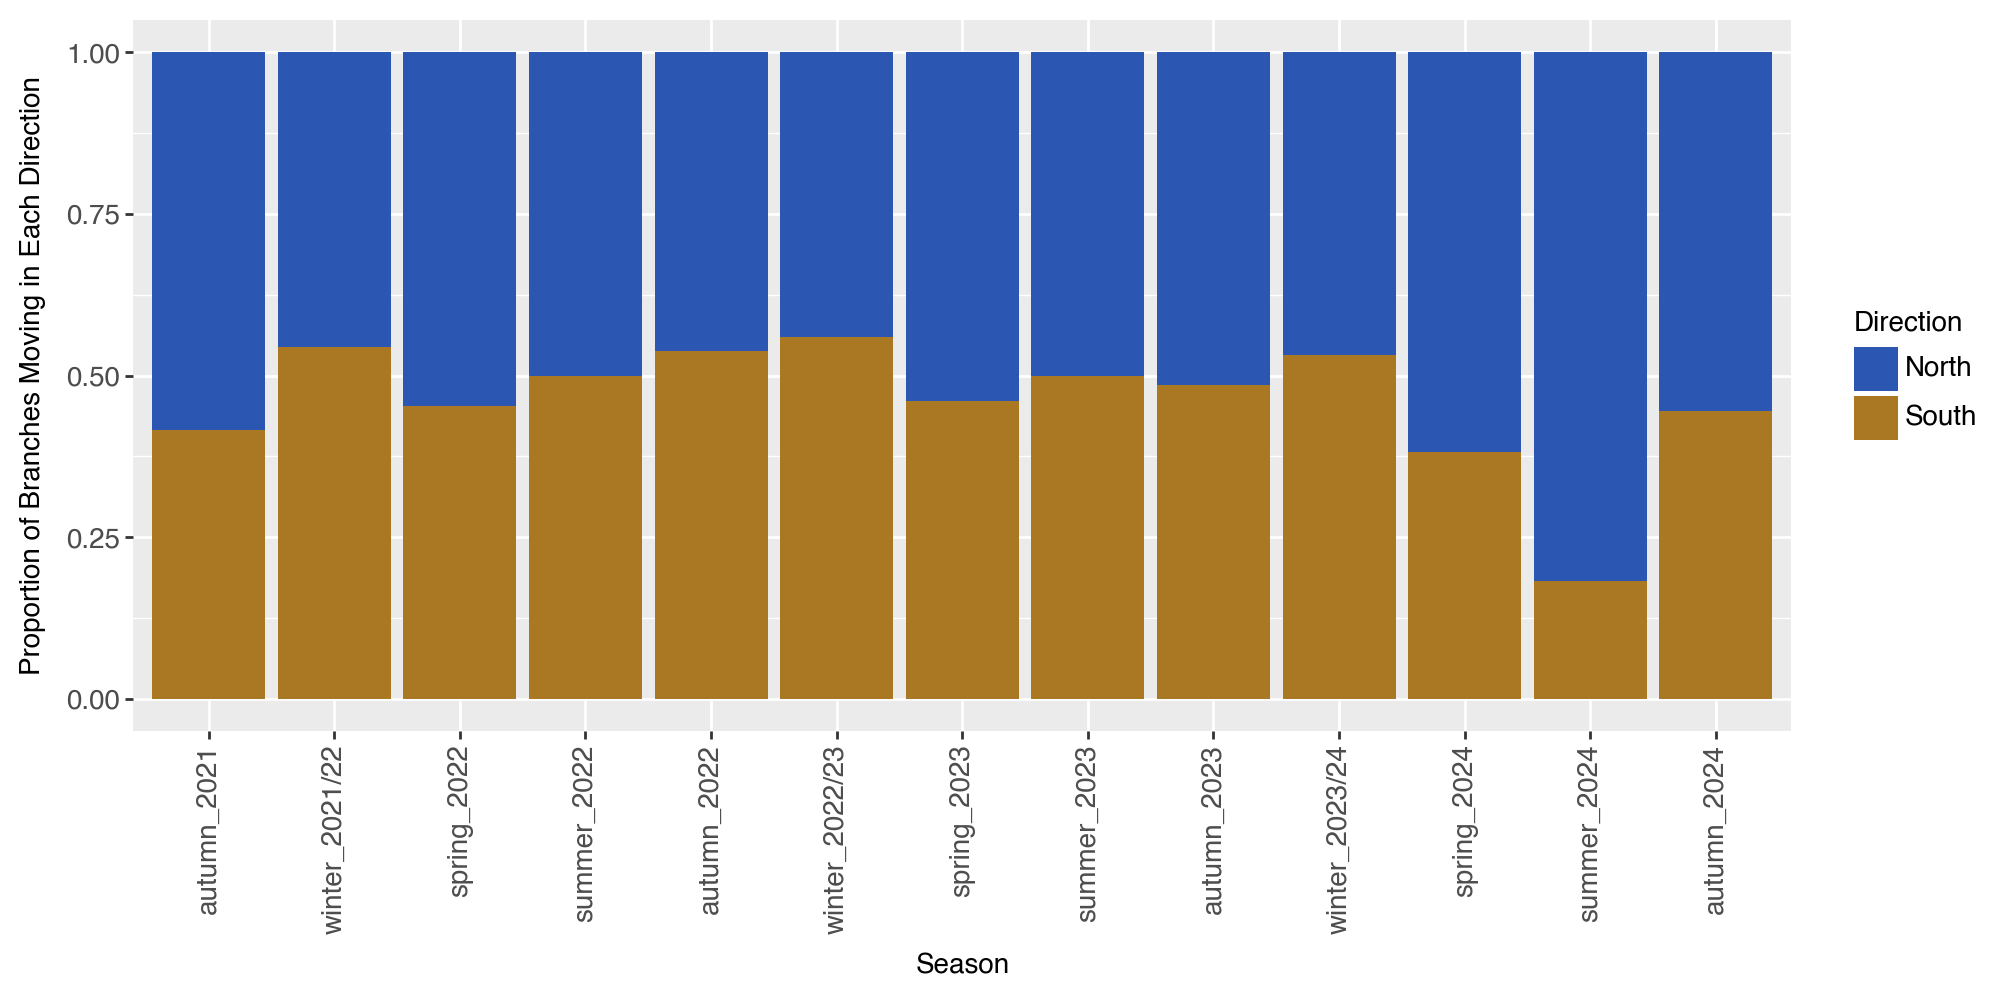

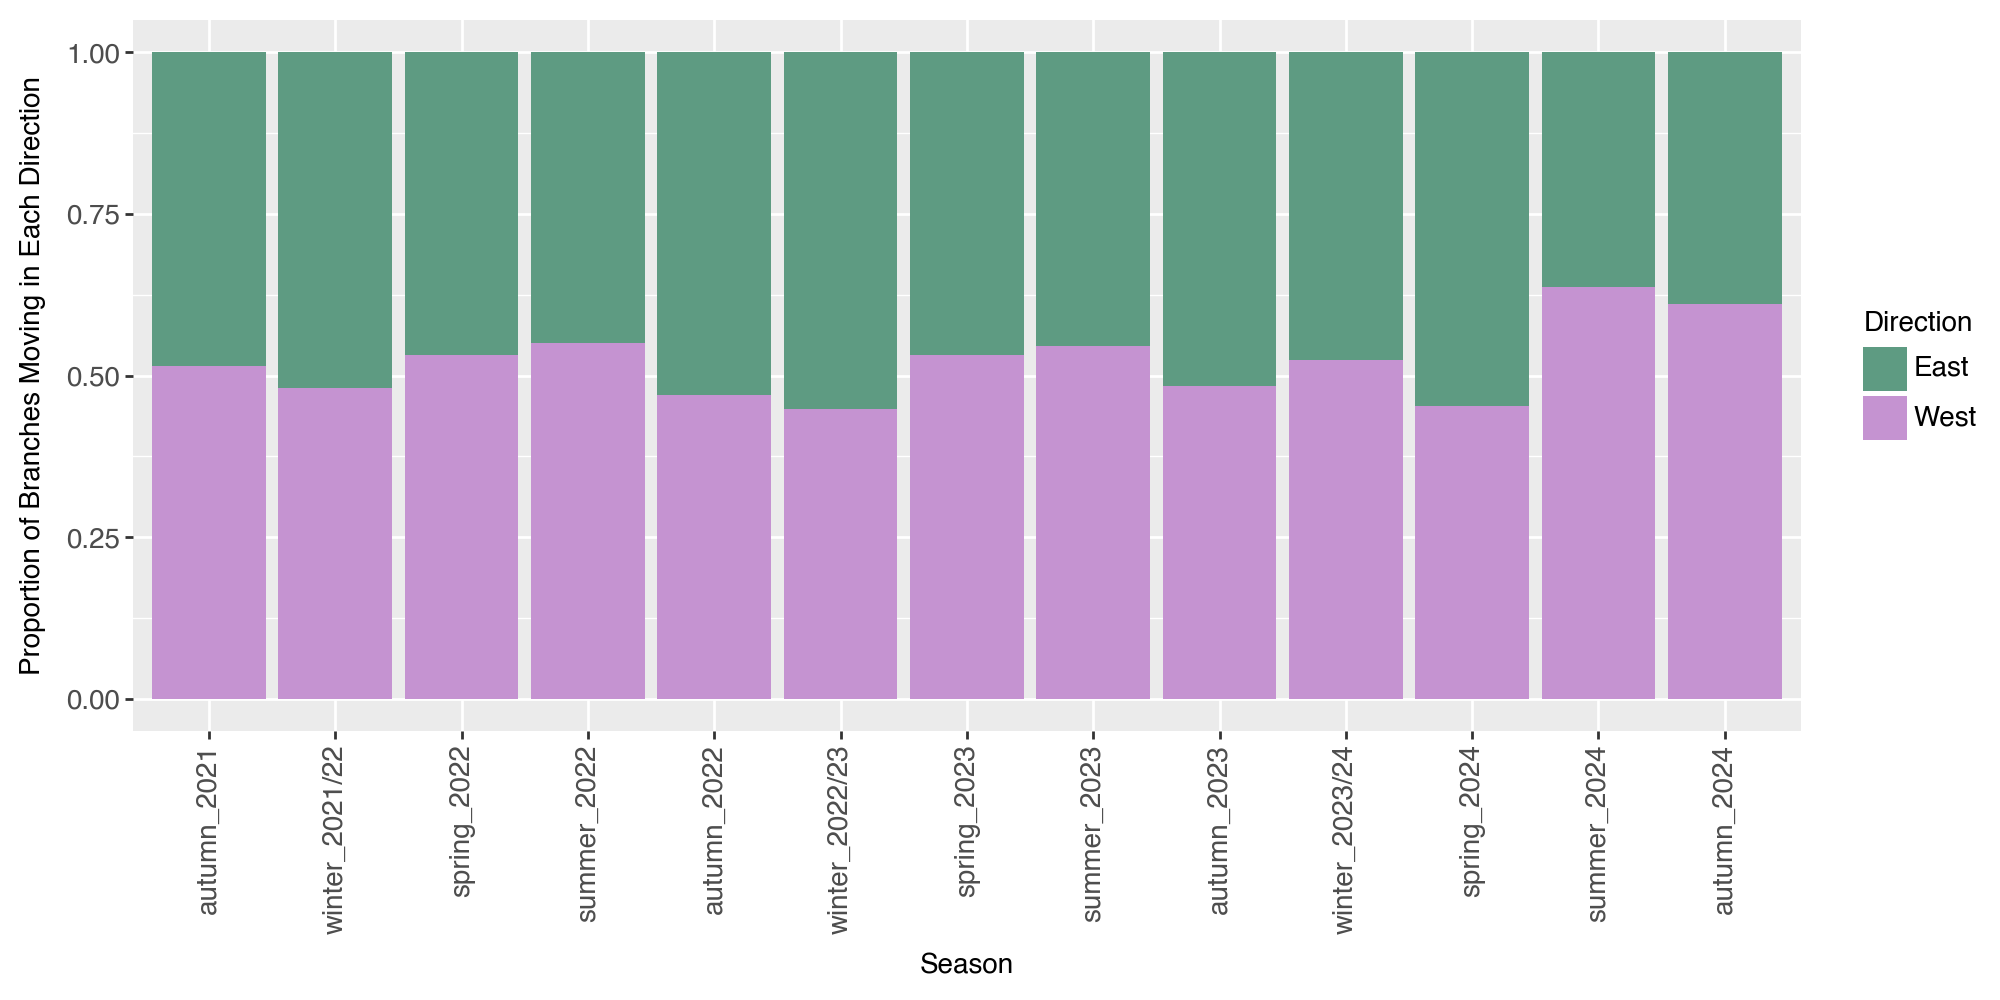

In [52]:
# Plot 3: Proportion of branchs moving north/south, east/west during each year and each season

season_year_order = ["autumn_2021", "winter_2021/22", "spring_2022", "summer_2022", "autumn_2022", "winter_2022/23", 
                     "spring_2023", "summer_2023", "autumn_2023", "winter_2023/24", "spring_2024", "summer_2024", 
                     "autumn_2024", "winter_2024"]
MCCDATA["season_year"] = pd.Categorical(MCCDATA["season_year"], categories=season_year_order, ordered=True)

prop_direction_latitude = (
    ggplot(MCCDATA, aes(x = "season_year", fill = "changeLat_direction"))
        + geom_bar(position = "fill")
        + scale_fill_manual(values={"north": "#2B57B3", "south": "#AA7722"}, name="Direction", 
                            labels={"north":"North", "south": "South"})
        + labs(x='Season', y='Proportion of Branches Moving in Each Direction')
        + theme(axis_text_x=element_text(rotation=90), text=element_text(size=10))
        + theme(figure_size=(10, 5))
    )

prop_direction_longitude = (
    ggplot(MCCDATA, aes(x = "season_year", fill = "changeLon_direction"))
        + geom_bar(position = "fill")
        + scale_fill_manual(values={"east": "#5E9B82", "west": "#C593D1"}, name="Direction", 
                            labels={"east":"East", "west": "West"})
        + labs(x='Season', y='Proportion of Branches Moving in Each Direction')
        + theme(axis_text_x=element_text(rotation=90), text=element_text(size=10))
        + theme(figure_size=(10, 5))
    )

prop_direction_latitude.show()
prop_direction_longitude.show()

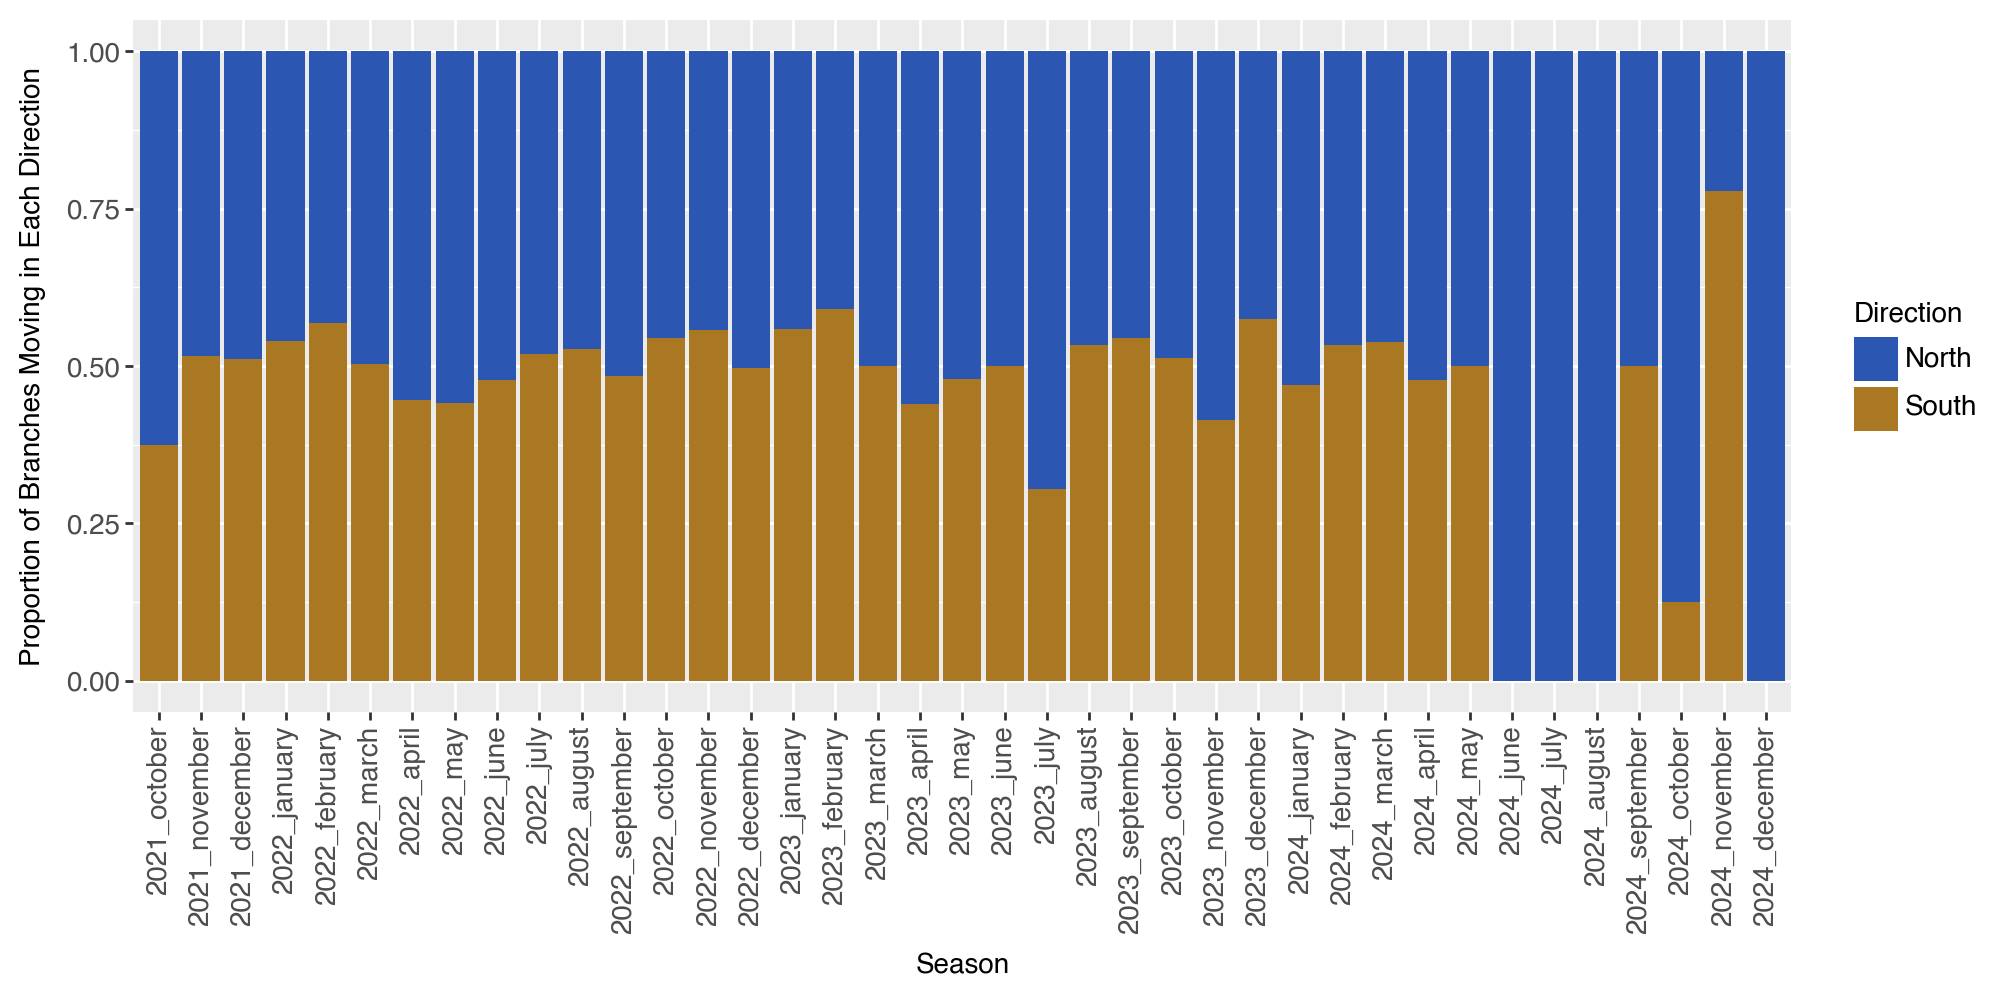

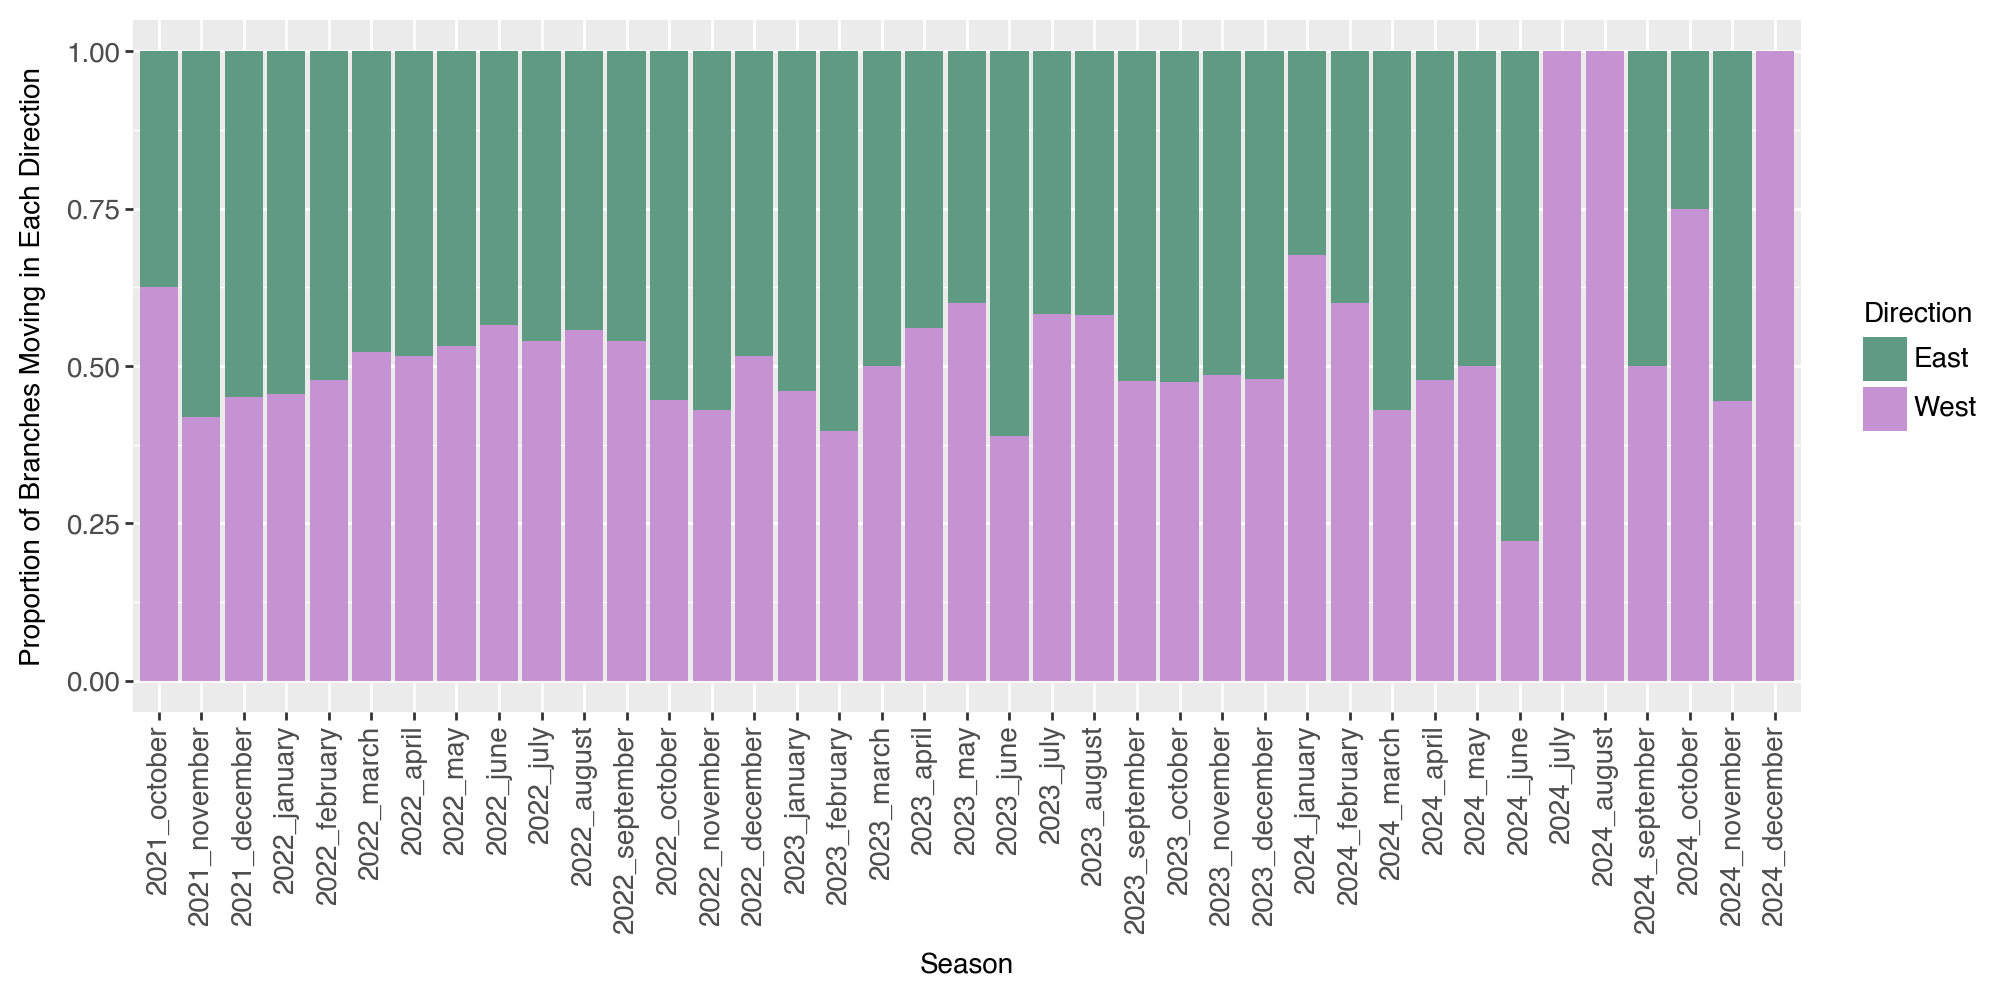

In [46]:
# Plot 3.5: Proportion of branchs moving north/south, east/west during each month

MCCDATA["month_year"] = MCCDATA["month_year"].astype(str)

month_order = ["2021_september", "2021_october","2021_november","2021_december", "2022_january", "2022_february", "2022_march", "2022_april", "2022_may", "2022_june",
               "2022_july", "2022_august", "2022_september", "2022_october", "2022_november", "2022_december","2023_january", "2023_february", "2023_march", "2023_april", 
               "2023_may", "2023_june", "2023_july", "2023_august", "2023_september", "2023_october", "2023_november", "2023_december", "2024_january", "2024_february", 
               "2024_march", "2024_april", "2024_may", "2024_june","2024_july", "2024_august", "2024_september", "2024_october", "2024_november", "2024_december"]

MCCDATA["month_year"] = pd.Categorical(MCCDATA["month_year"], categories=month_order, ordered=True)

prop_direction_latitude_month = (
    ggplot(MCCDATA, aes(x = "month_year", fill = "changeLat_direction"))
        + geom_bar(position = "fill")
        + scale_fill_manual(values={"north": "#2B57B3", "south": "#AA7722"}, name="Direction", 
                            labels={"north":"North", "south": "South"})
        + labs(x='Season', y='Proportion of Branches Moving in Each Direction')
        + theme(axis_text_x=element_text(rotation=90), text=element_text(size=10))
        + theme(figure_size=(10, 5))
    )

prop_direction_longitude_month = (
    ggplot(MCCDATA, aes(x = "month_year", fill = "changeLon_direction"))
        + geom_bar(position = "fill")
        + scale_fill_manual(values={"east": "#5E9B82", "west": "#C593D1"}, name="Direction", 
                            labels={"east":"East", "west": "West"})
        + labs(x='Season', y='Proportion of Branches Moving in Each Direction')
        + theme(axis_text_x=element_text(rotation=90), text=element_text(size=10))
        + theme(figure_size=(10, 5))
    )

prop_direction_latitude_month.show()
prop_direction_longitude_month.show()

In [96]:
# # Maybe this will come in handy... at some point
# # Makes a dataframe with the proportion in each column

# # Make a new dataframe and calculate the proportion of each direction
# directions_df = pd.DataFrame({"season_year": ["autumn_2021", "winter_2021/22", "spring_2022", "summer_2022", "autumn_2022",
#                              "winter_2022/23", "spring_2023", "summer_2023", "autumn_2023",
#                              "winter_2023/24", "spring_2024", "summer_2024", "autumn_2024", "winter_2024"]})

# for season, group_df in mcc_seas_mon_withDirections.groupby("season_year"):
   
#     total = len(group_df)
    
#     prop_north = len(group_df[group_df["changeLat_direction"] == "north"]) / total
#     prop_south = len(group_df[group_df["changeLat_direction"] == "south"]) / total
#     prop_east  = len(group_df[group_df["changeLon_direction"] == "east"]) / total
#     prop_west  = len(group_df[group_df["changeLon_direction"] == "west"]) / total

#     directions_df.loc[directions_df["season_year"] == season, "north"] = prop_north
#     directions_df.loc[directions_df["season_year"] == season, "south"] = prop_south
#     directions_df.loc[directions_df["season_year"] == season, "east"]  = prop_east
#     directions_df.loc[directions_df["season_year"] == season, "west"]  = prop_west 

/Users/claramal/miniconda3/lib/python3.11/site-packages/pandas/core/arraylike.py:399: RuntimeWarning: invalid value encountered in log10
/Users/claramal/miniconda3/lib/python3.11/site-packages/plotnine/layer.py:364: PlotnineWarning: geom_point : Removed 101 rows containing missing values.


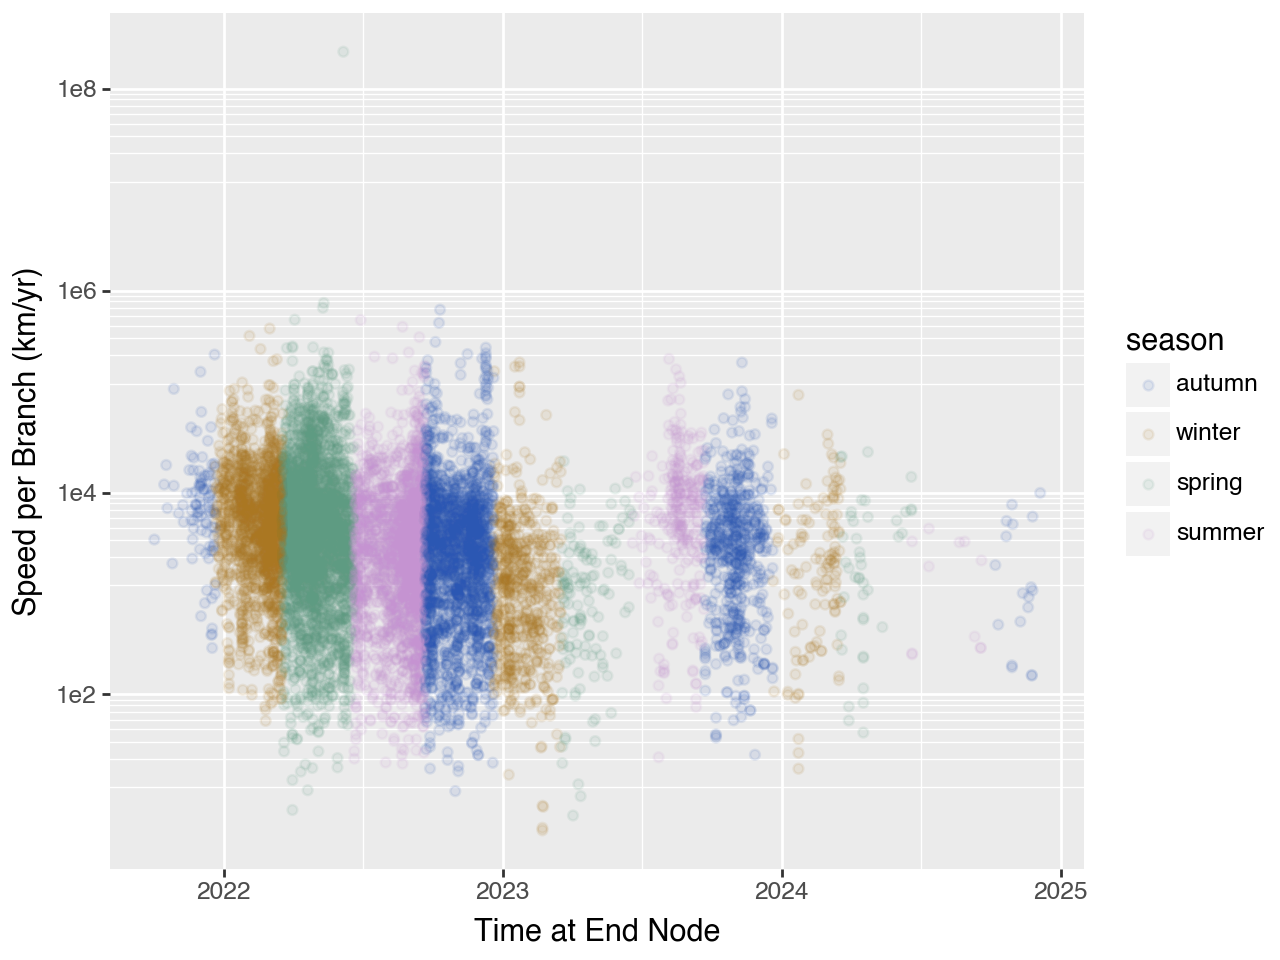

/Users/claramal/miniconda3/lib/python3.11/site-packages/plotnine/layer.py:284: PlotnineWarning: stat_ydensity : Removed 2227 rows containing non-finite values.


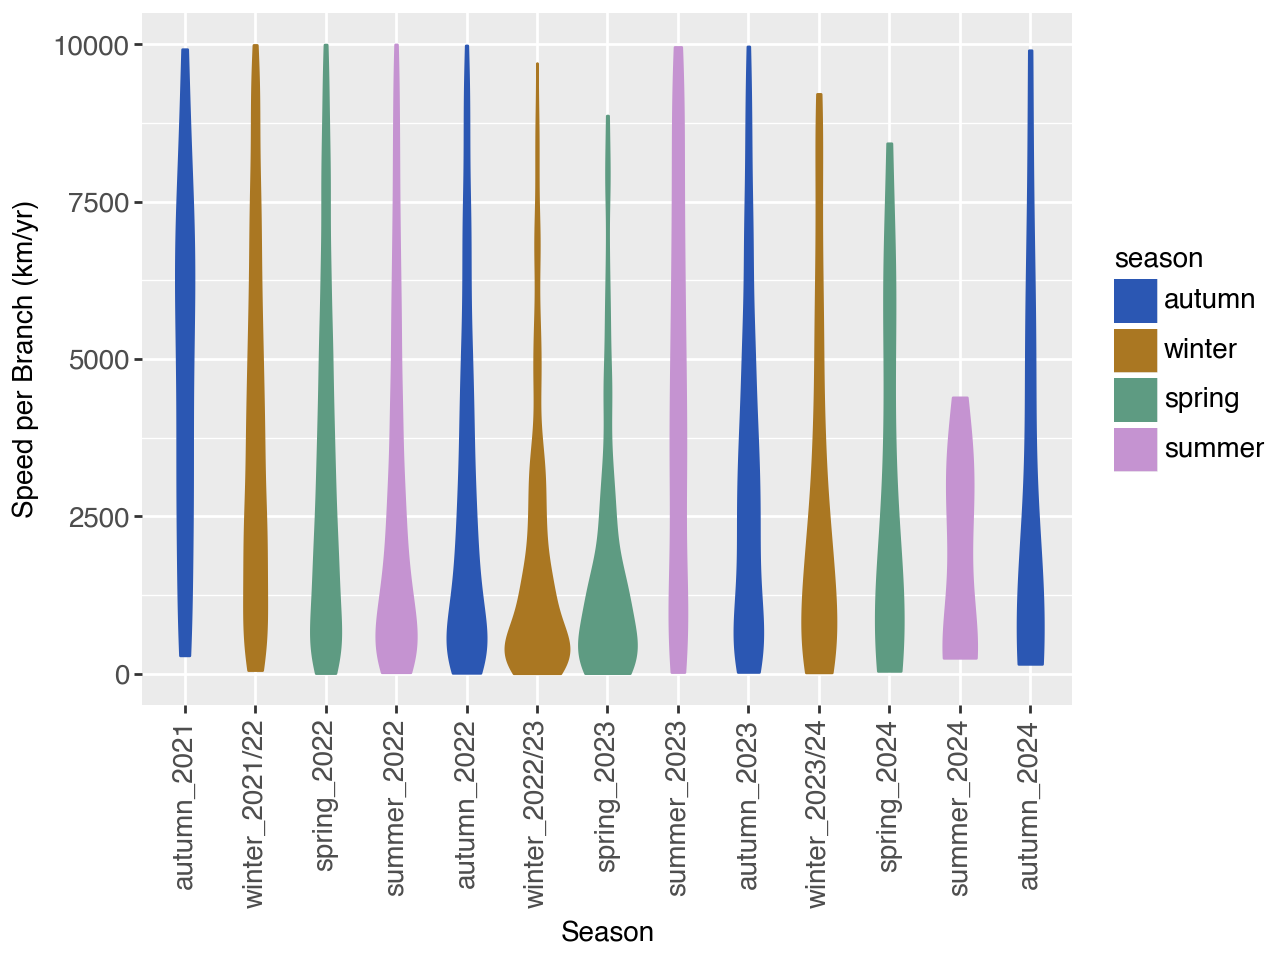

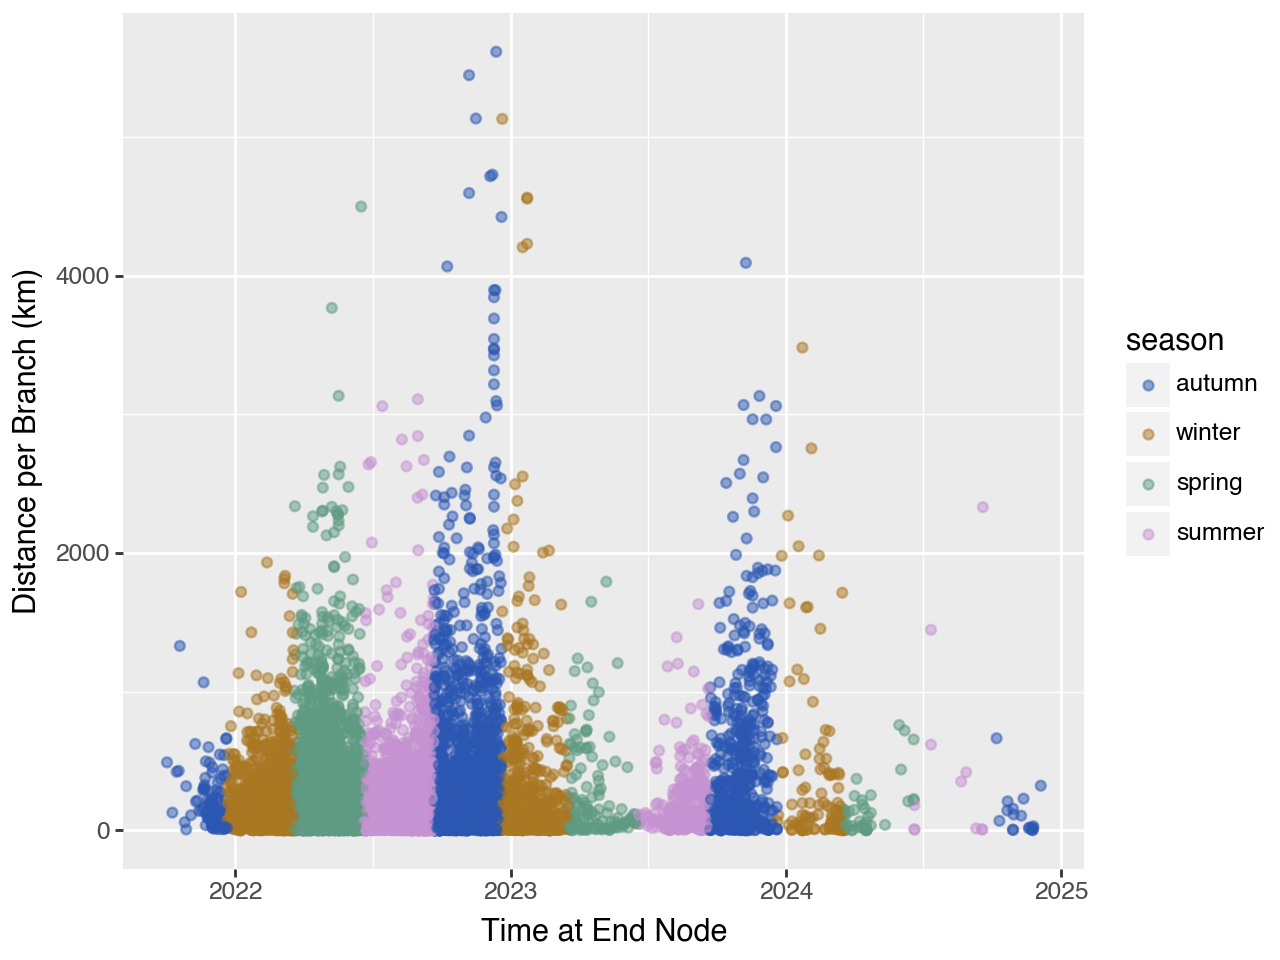

/Users/claramal/miniconda3/lib/python3.11/site-packages/pandas/core/arraylike.py:399: RuntimeWarning: invalid value encountered in log10


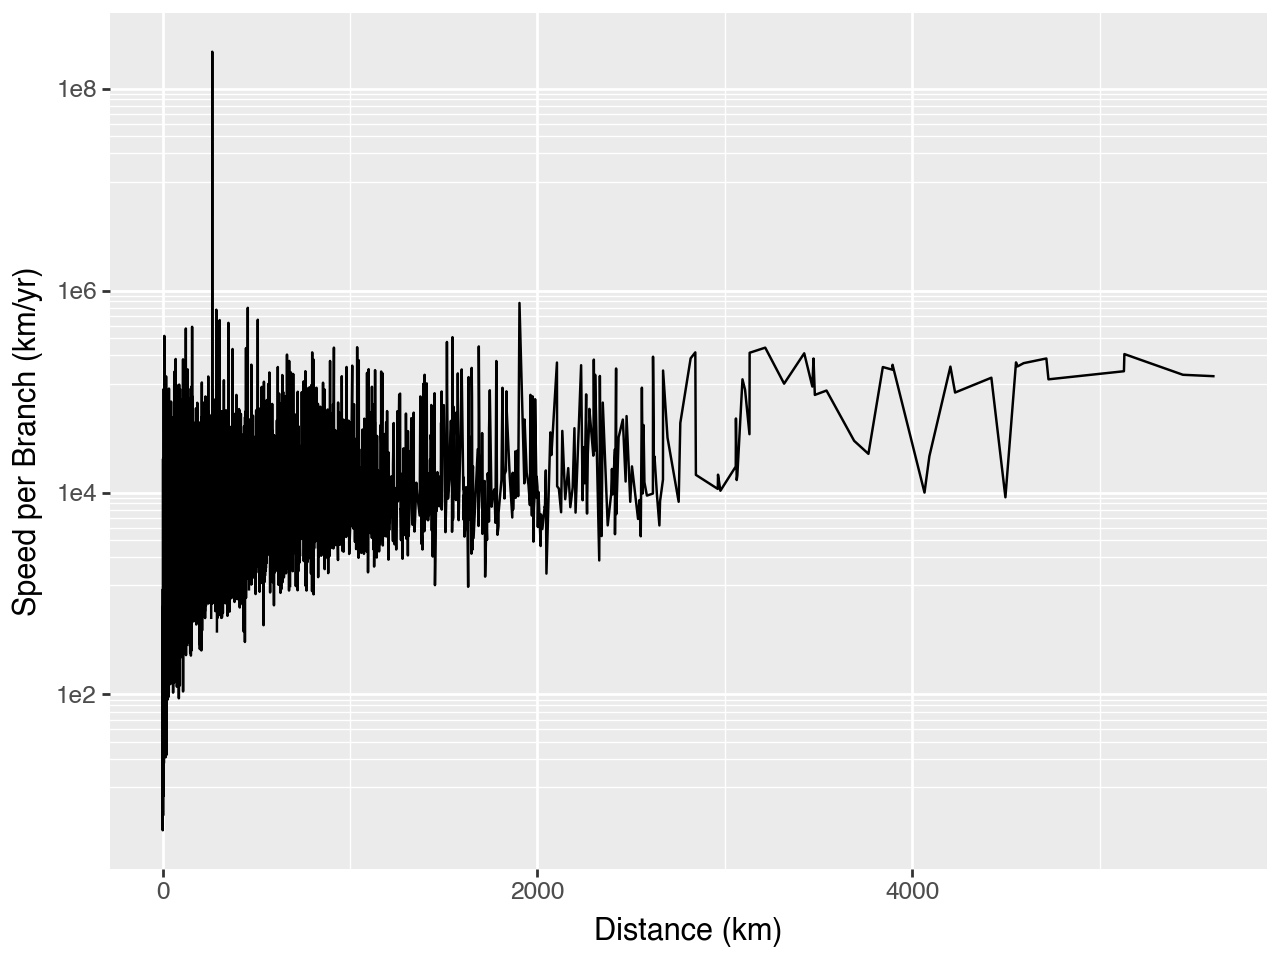

In [53]:
# Plots 3, 4, 5: speed and distance over time 

speed_over_time = (
    ggplot(MCCDATA, aes(x = "endYear", y = "branchSpeed", color = "season")) 
    + geom_point(alpha=0.1)
#    + facet_wrap("endYear_whole")
    + scale_color_manual(values=season_colors)
    + scale_y_log10()
    + labs(x = "Time at End Node", y = "Speed per Branch (km/yr)")
)

speed_per_season = (
    ggplot(MCCDATA, aes(x = "season_year", y = "branchSpeed", color = "season", fill = "season"))
    + geom_violin()
    + ylim(-5, 10000)
    + scale_fill_manual(values=season_colors)
    + scale_color_manual(values=season_colors)
    + theme(axis_text_x=element_text(rotation=90), text=element_text(size=10))
    + labs(x = "Season", y = "Speed per Branch (km/yr)")
)

dist_over_time = (
    ggplot(MCCDATA, aes(x = "endYear", y = "dist_km", color = "season")) 
    + geom_point(alpha=0.5)
    + scale_color_manual(values=season_colors)
    # + scale_y_log10()
#    + facet_wrap("endYear_whole")
    + labs(x = "Time at End Node", y = "Distance per Branch (km)")
)

dist_vs_speed = (
    ggplot(MCCDATA, aes(x = "dist_km", y = "branchSpeed"))
    + geom_line()
    + scale_y_log10()
    + labs(x = "Distance (km)", y = "Speed per Branch (km/yr)")
)

speed_over_time.show()
speed_per_season.show()
dist_over_time.show()
#dist_over_time.save(filename = './SERAPHIM/nov2021-2024_no-suliformes/output_plots/distance_over_time.pdf', height=7, width=10, units = 'in', dpi=750)
dist_vs_speed.show()

/Users/claramal/miniconda3/lib/python3.11/site-packages/plotnine/layer.py:284: PlotnineWarning: stat_bin : Removed 35 rows containing non-finite values.
/Users/claramal/miniconda3/lib/python3.11/site-packages/plotnine/layer.py:364: PlotnineWarning: geom_histogram : Removed 2 rows containing missing values.


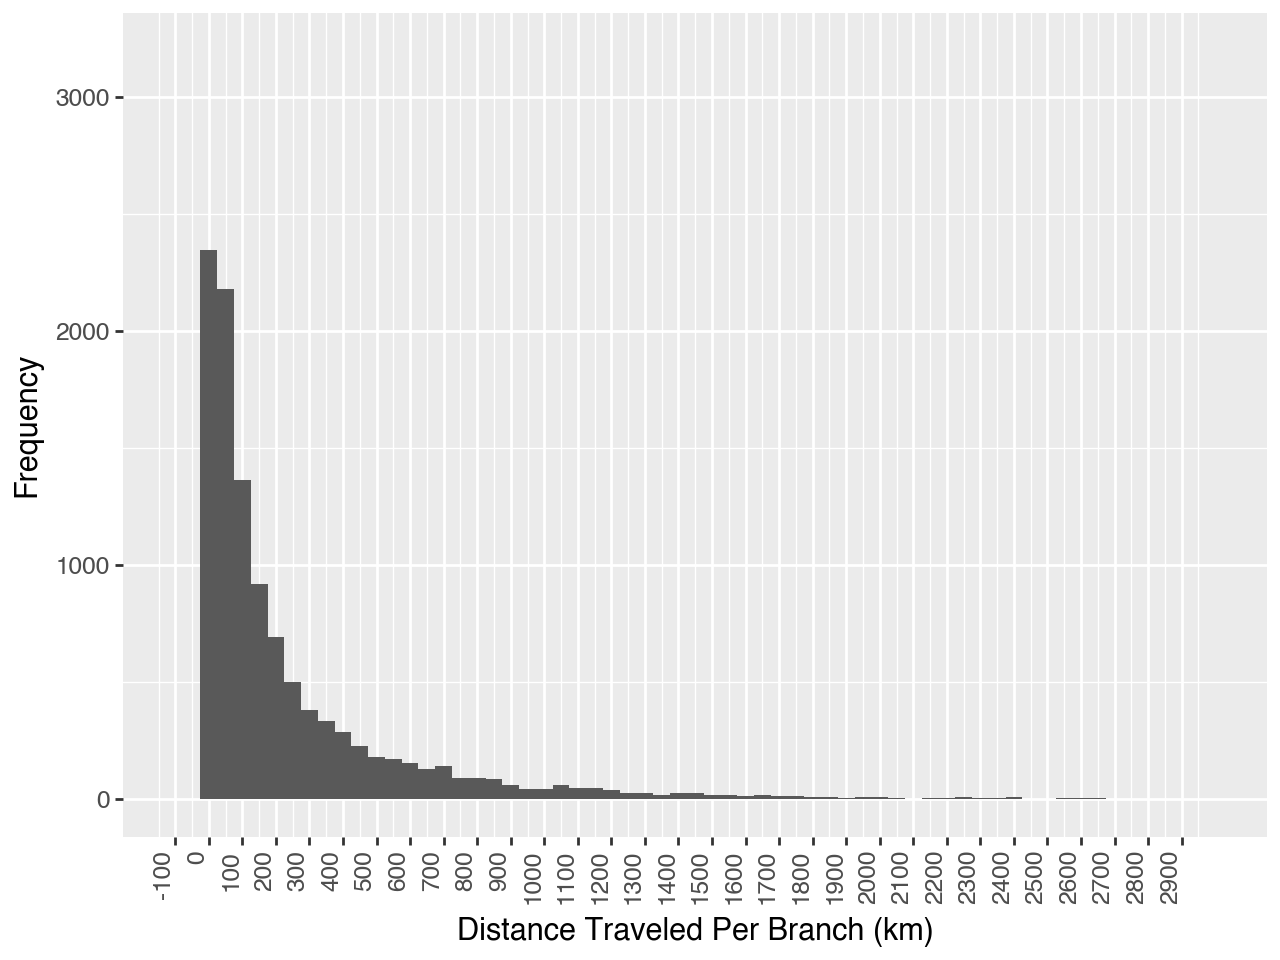

5287


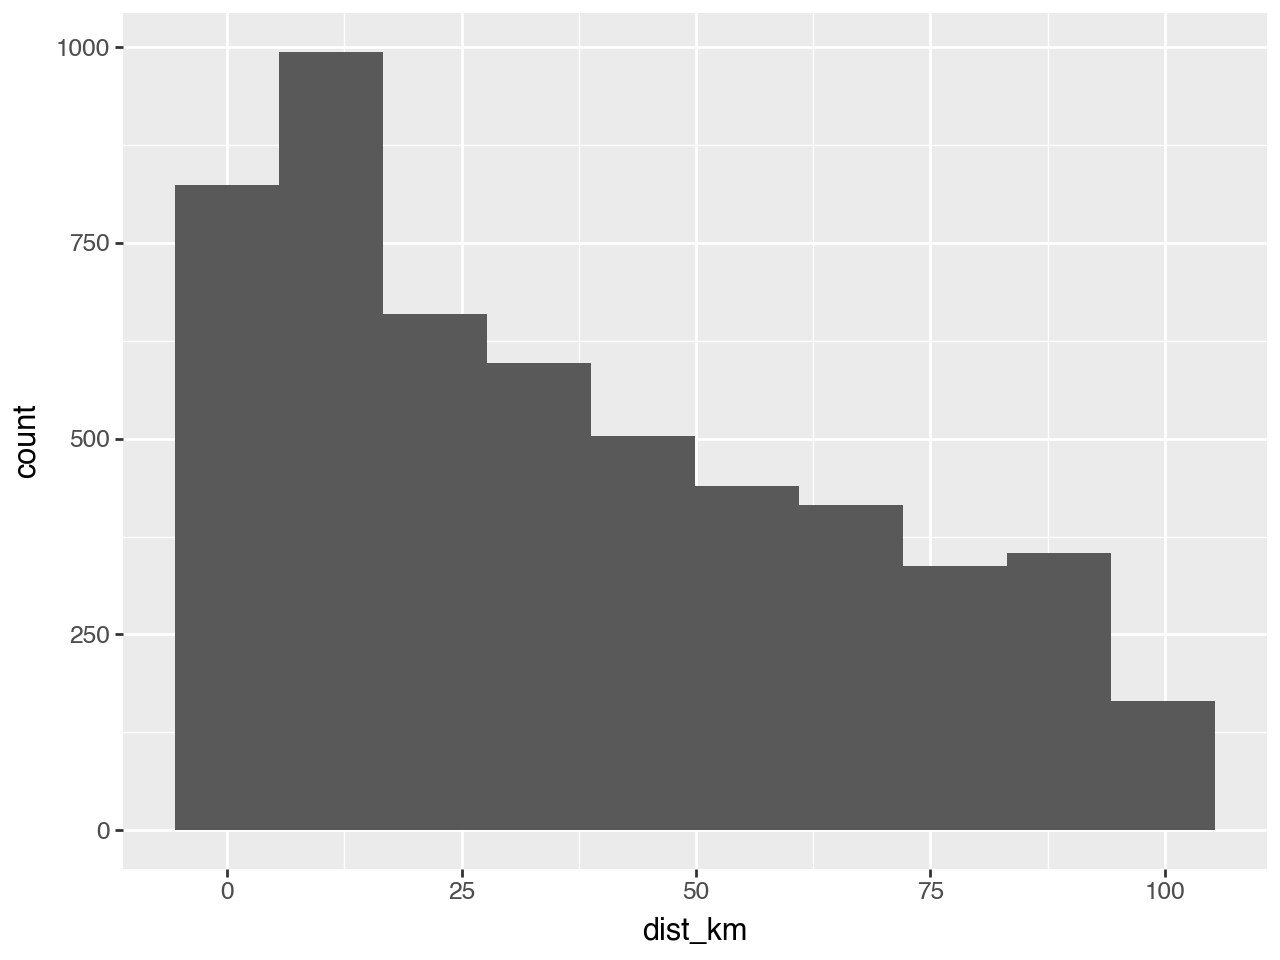

In [52]:
# Plot 6: Histogram of distance (km) per branch

dist_freq = (
    ggplot(MCCDATA, aes(x = "dist_km")) 
    + geom_histogram(binwidth = 50) # Each bin is 50 km
    + scale_x_continuous(limits=(-100, 3000), breaks=range(-100, 2999, 100))
    + ylim(0, 3200)
    + labs(x = "Distance Traveled Per Branch (km)", y = "Frequency")
    + theme(axis_text_x=element_text(rotation=90, hjust=1))
)

dist_freq.show()

# I'm just curious what it looks like below 100 km

just_curious = mcc_seas_mon_state_flyway_upt2[mcc_seas_mon_state_flyway_upt2["dist_km"] < 100]
print(len(just_curious))
just_curious = (
    ggplot(just_curious, aes(x = "dist_km"))
    + geom_histogram(bins = 10)
)
just_curious.show()

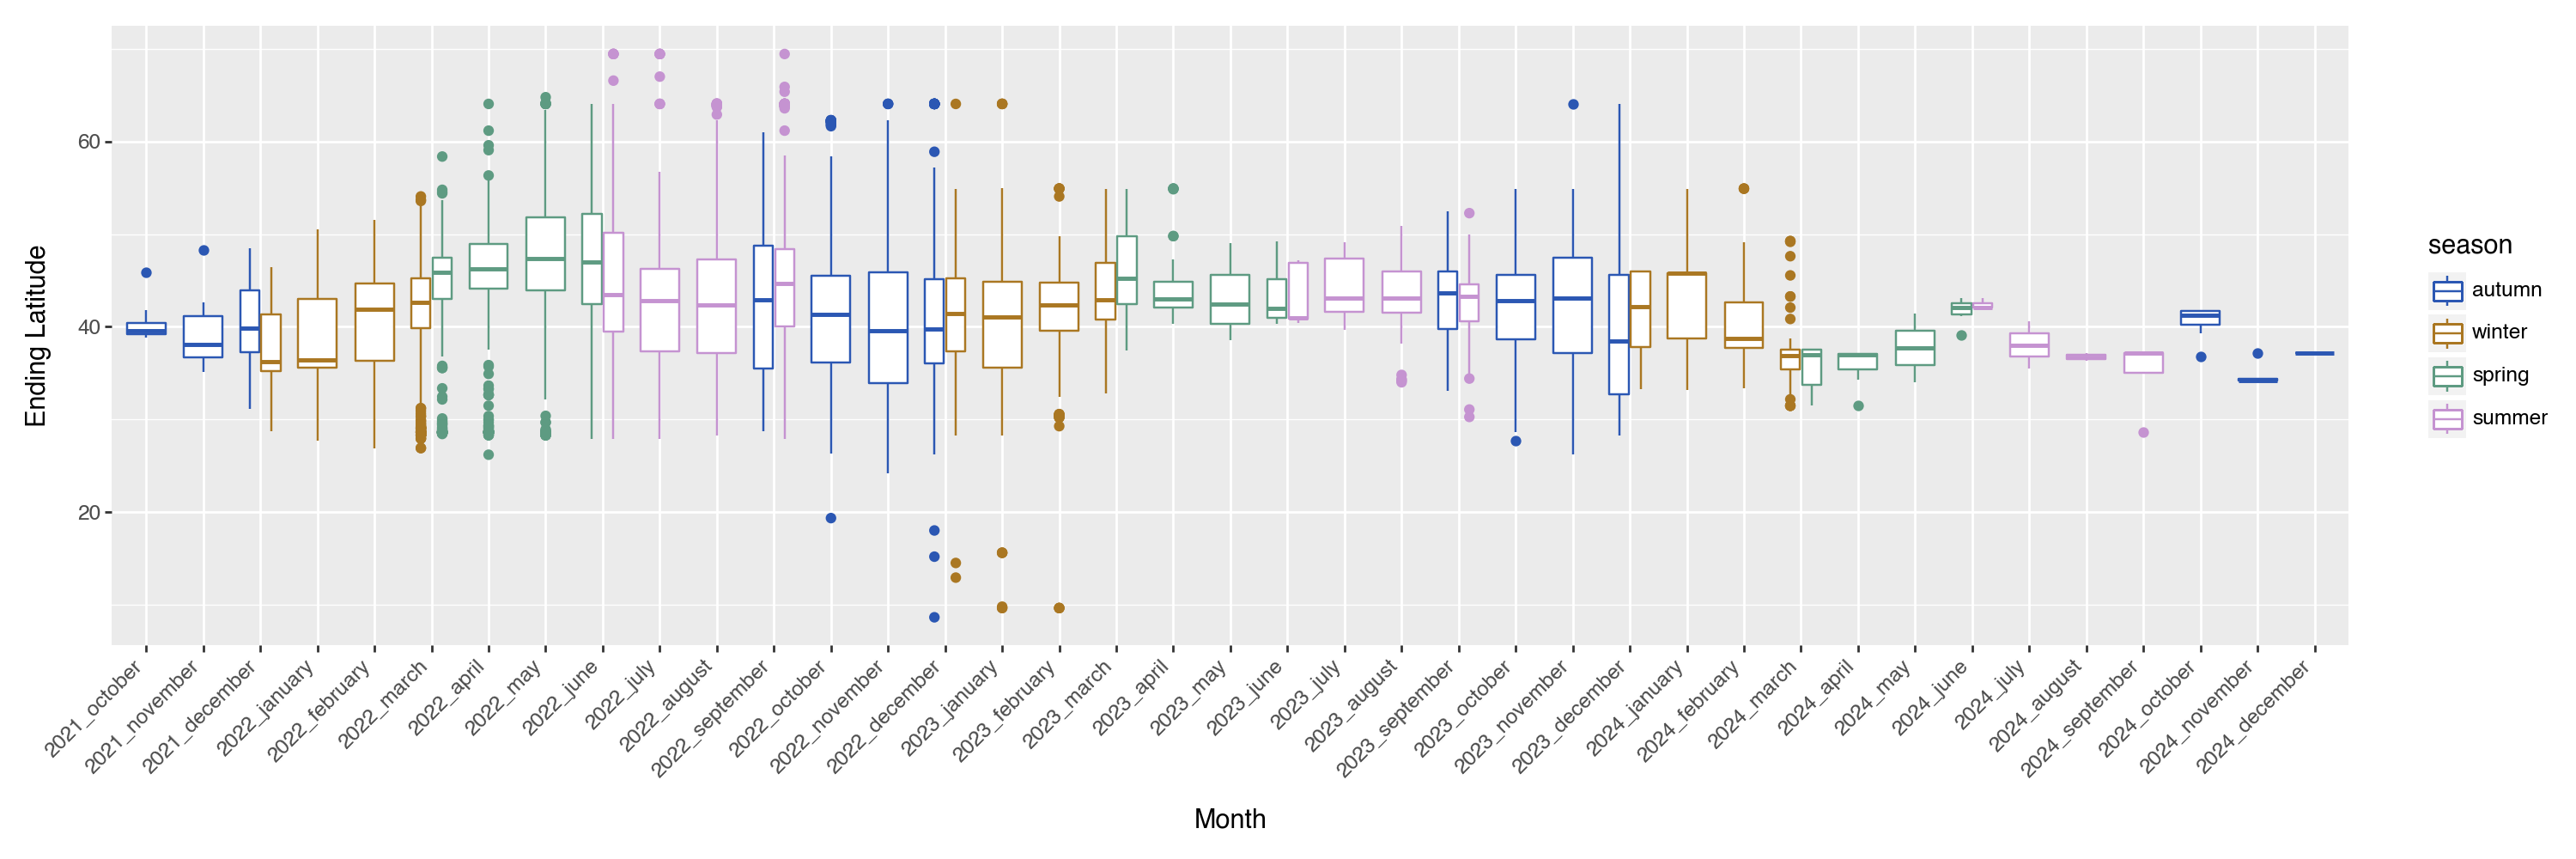

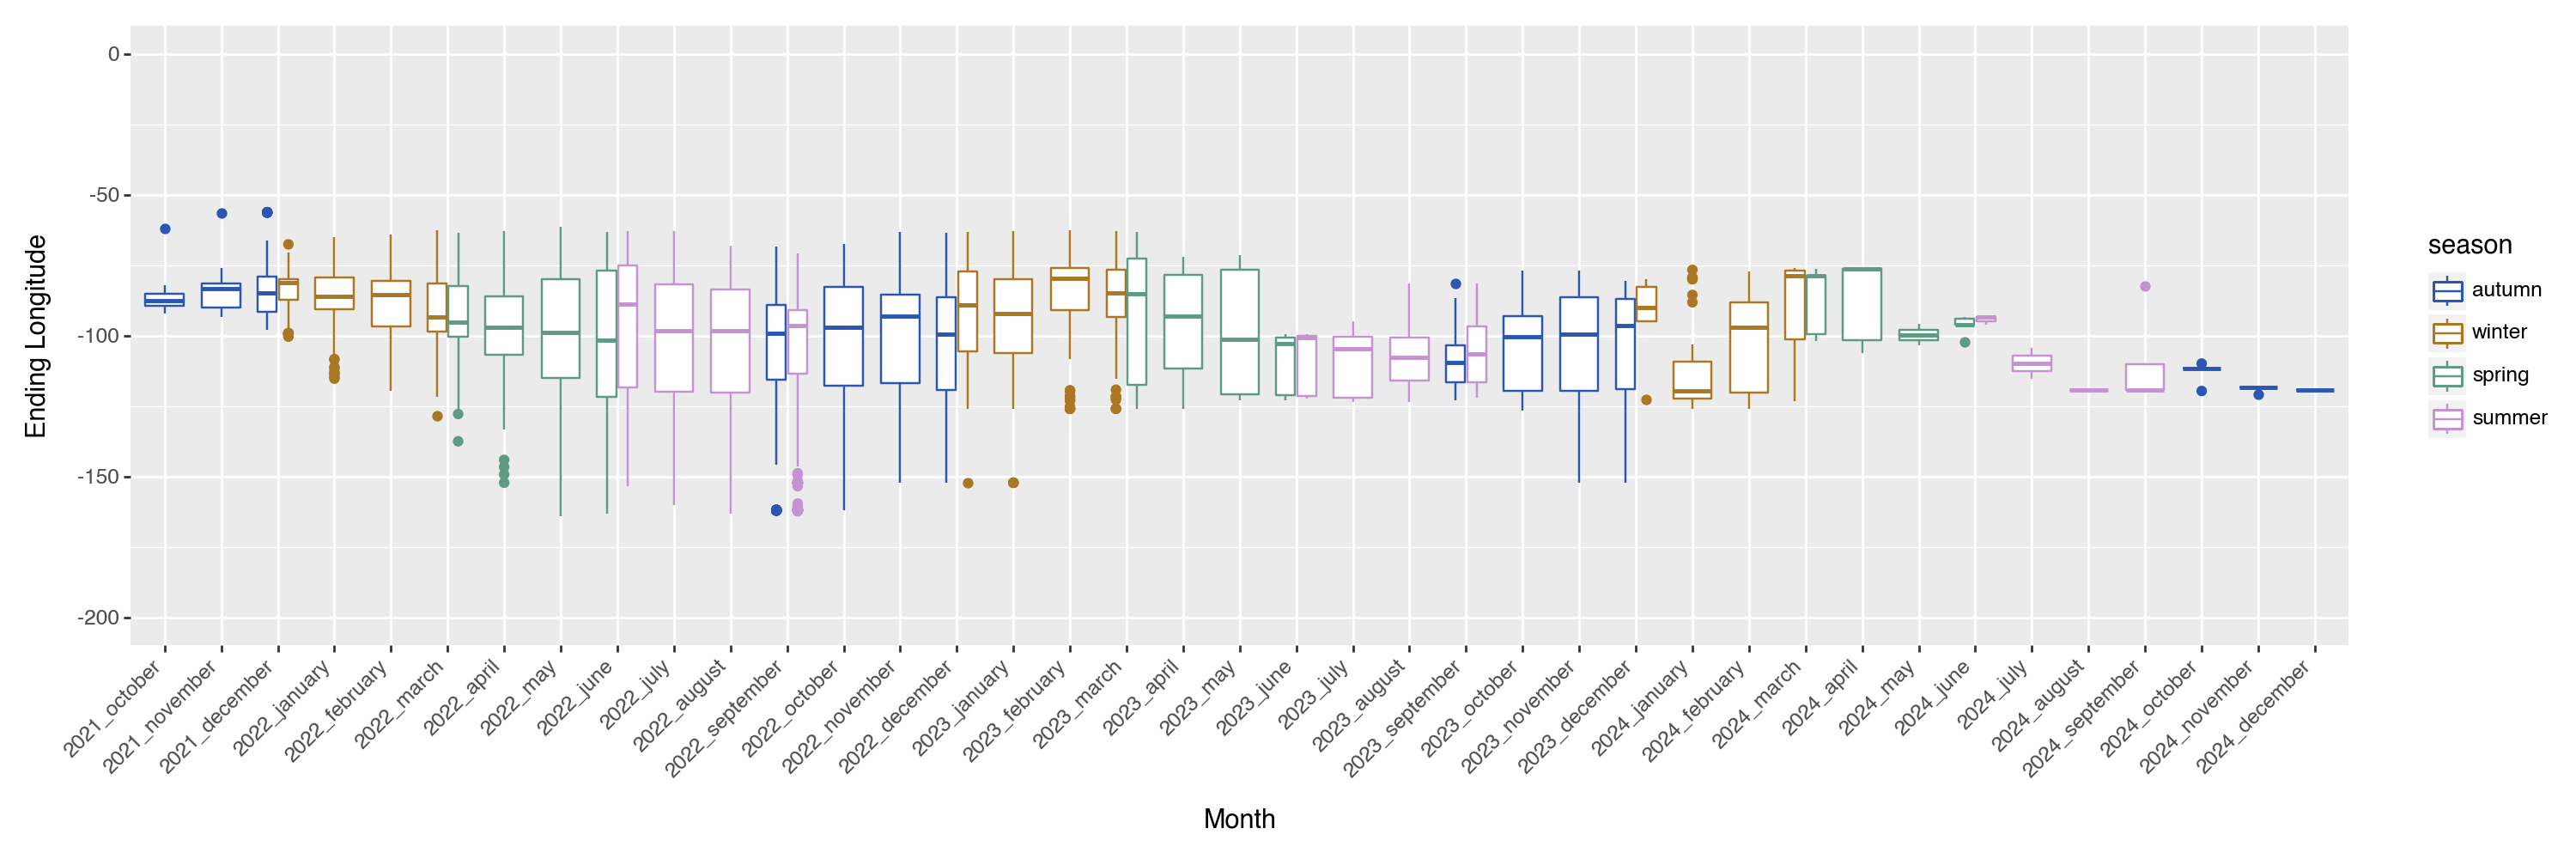

In [53]:
# Plot 8: average lat and lon per month

avg_latitude = (
    ggplot(MCCDATA)
#    + geom_boxplot(aes(x = "factor(month_year)", y = "startLat", color = "season"))
    + geom_boxplot(aes(x = "factor(month_year)", y = "endLat", color = "season"))
    + labs(x = "Month", y = "Ending Latitude")
    + scale_color_manual(values = season_colors)
    + theme(axis_text_x=element_text(rotation=45, hjust=1), figure_size = (15, 5))
)


avg_longitude = (
    ggplot(MCCDATA)
#    + geom_boxplot(aes(x = "factor(month_year)", y = "startLon", color = "season"))
    + geom_boxplot(aes(x = "factor(month_year)", y = "endLon", color = "season"))
    + labs(x = "Month", y = "Ending Longitude")
    + scale_color_manual(values = season_colors)
    + ylim(-200, 0)
    + theme(axis_text_x=element_text(rotation=45, hjust=1), figure_size = (15, 5))
)

avg_latitude.show()
avg_longitude.show()

  changeFlyway  proportion
0           no    0.797073
1          yes    0.117265


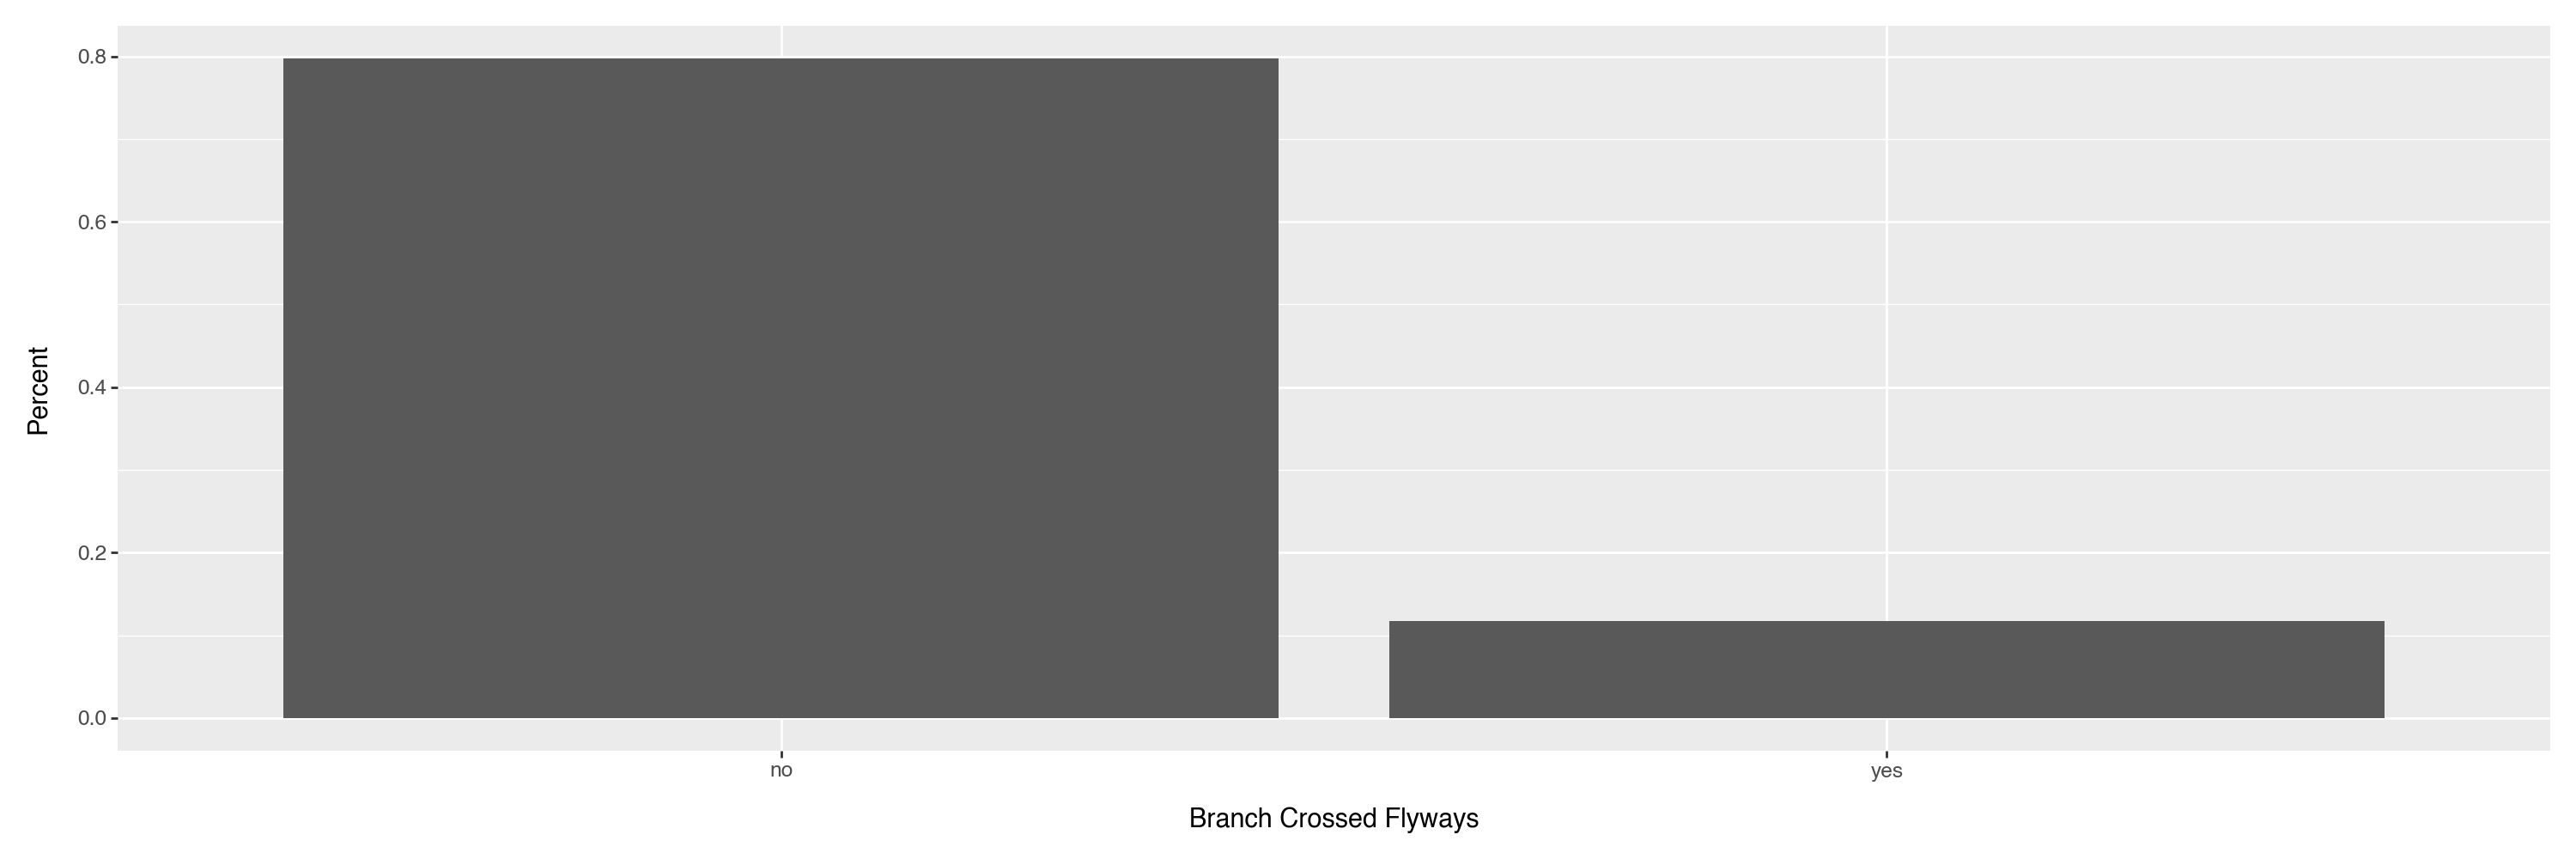

In [54]:
# Plot 9: the proportion of branches that cross flyways

prop_df = pd.DataFrame(["no", "yes"]).rename({0:"changeFlyway"}, axis = 1)

# prop_df.loc[prop_df["changeFlyway"] == "no", "value"] = len(mcc_seas_mon_flyways_upt2.loc[mcc_seas_mon_flyways_upt2["changeFlyway"] == "no"])
# prop_df.loc[prop_df["changeFlyway"] == "yes", "value"] = len(mcc_seas_mon_flyways_upt2.loc[mcc_seas_mon_flyways_upt2["changeFlyway"] == "yes"])

prop_df.loc[prop_df["changeFlyway"] == "no", "proportion"] = (len(MCCDATA.loc[MCCDATA["changeFlyway"] == "no"])) / 12024
prop_df.loc[prop_df["changeFlyway"] == "yes", "proportion"] = (len(MCCDATA.loc[MCCDATA["changeFlyway"] == "yes"])) / 12024

print(prop_df)

proportion_changeFlyway = (
    ggplot(prop_df, aes(x = "changeFlyway", y = "proportion"))
    + geom_col()
    + labs(x = "Branch Crossed Flyways", y = "Percent")
    + theme(figure_size = (15, 5))
)

proportion_changeFlyway.show()

/Users/claramal/miniconda3/lib/python3.11/site-packages/plotnine/layer.py:284: PlotnineWarning: stat_bin : Removed 35 rows containing non-finite values.
/Users/claramal/miniconda3/lib/python3.11/site-packages/plotnine/layer.py:364: PlotnineWarning: geom_histogram : Removed 4 rows containing missing values.


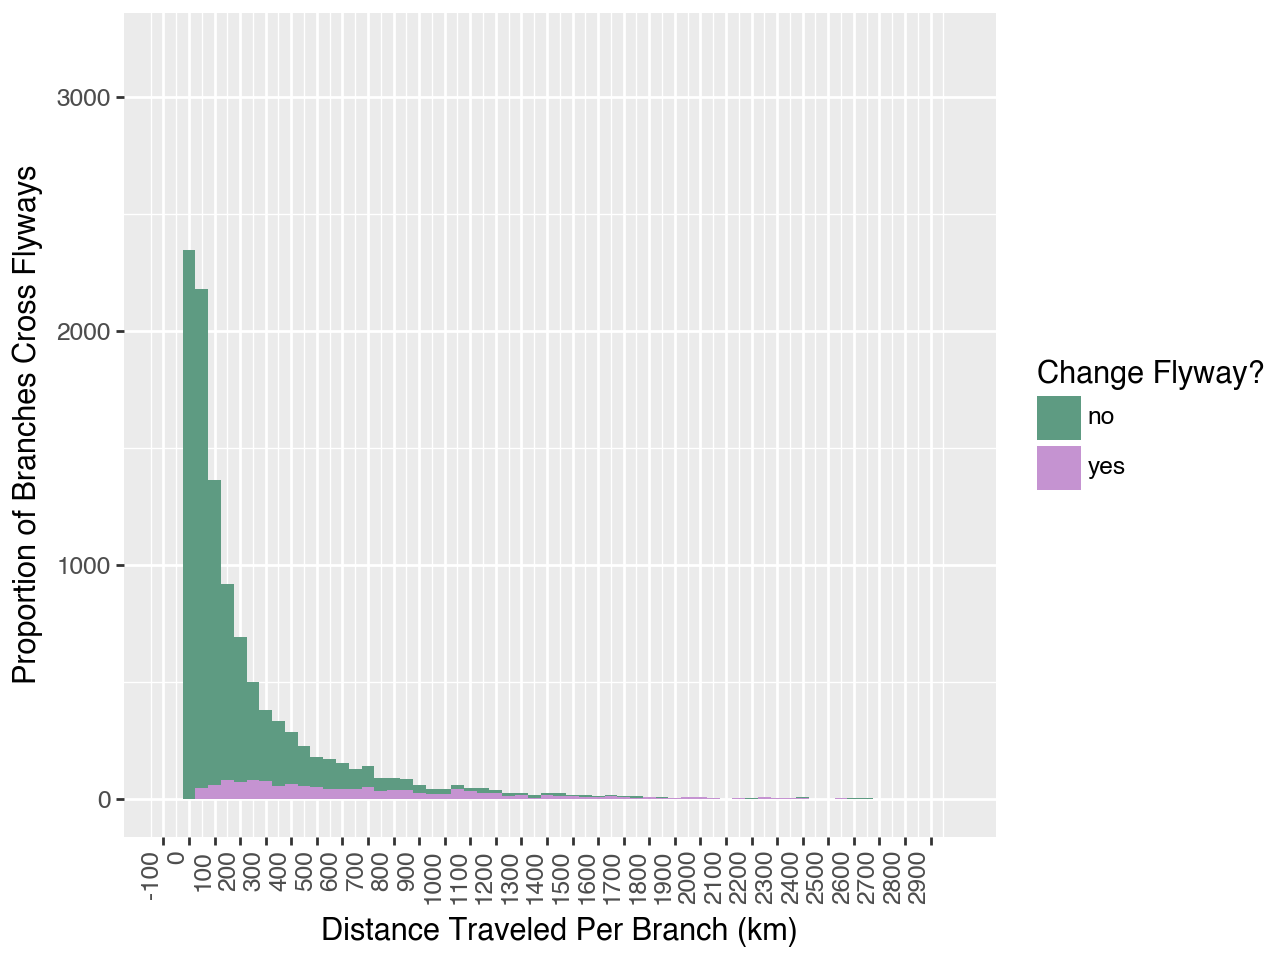

/Users/claramal/miniconda3/lib/python3.11/site-packages/plotnine/layer.py:284: PlotnineWarning: stat_bin : Removed 35 rows containing non-finite values.
/Users/claramal/miniconda3/lib/python3.11/site-packages/pandas/core/arraylike.py:399: RuntimeWarning: divide by zero encountered in log10
/Users/claramal/miniconda3/lib/python3.11/site-packages/pandas/core/arraylike.py:399: RuntimeWarning: divide by zero encountered in log10
/Users/claramal/miniconda3/lib/python3.11/site-packages/plotnine/layer.py:364: PlotnineWarning: geom_histogram : Removed 4 rows containing missing values.


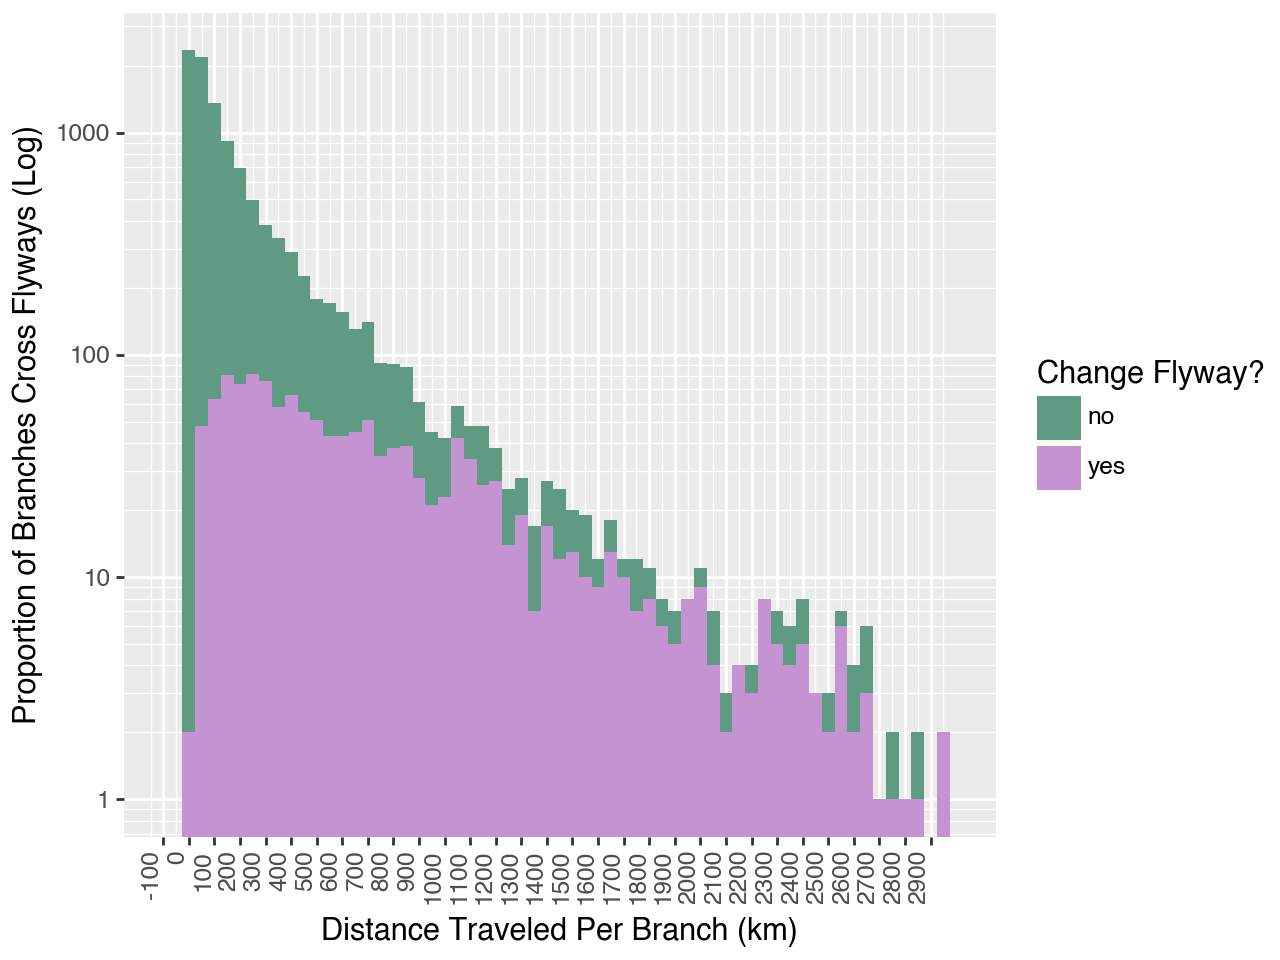

In [55]:
# Plot 10: On a histogram of distance traveled, what proportion cross flyways

dist_changeFlyway = (
    ggplot(MCCDATA, aes(x = "dist_km", fill = "changeFlyway"))
    + geom_histogram(binwidth = 50)
    + scale_fill_manual(values={"no": "#5E9B82", "yes": "#C593D1"}, name="Change Flyway?")
    + scale_x_continuous(limits=(-100, 3000), breaks=range(-100, 2999, 100))
    # + scale_y_log10()
    + ylim(0, 3200)
    + labs(x = "Distance Traveled Per Branch (km)", y = "Proportion of Branches Cross Flyways")
    + theme(axis_text_x=element_text(rotation=90, hjust=1))
)

dist_changeFlyway_logged = (
    ggplot(MCCDATA, aes(x = "dist_km", fill = "changeFlyway"))
    + geom_histogram(binwidth = 50)
    + scale_fill_manual(values={"no": "#5E9B82", "yes": "#C593D1"}, name="Change Flyway?")
    + scale_x_continuous(limits=(-100, 3000), breaks=range(-100, 2999, 100))
    + scale_y_log10()
    # + ylim(0, 3200)
    + labs(x = "Distance Traveled Per Branch (km)", y = "Proportion of Branches Cross Flyways (Log)")
    + theme(axis_text_x=element_text(rotation=90, hjust=1))
)

dist_changeFlyway.show()
dist_changeFlyway_logged.show()

/Users/claramal/miniconda3/lib/python3.11/site-packages/plotnine/layer.py:284: PlotnineWarning: stat_density : Removed 2227 rows containing non-finite values.


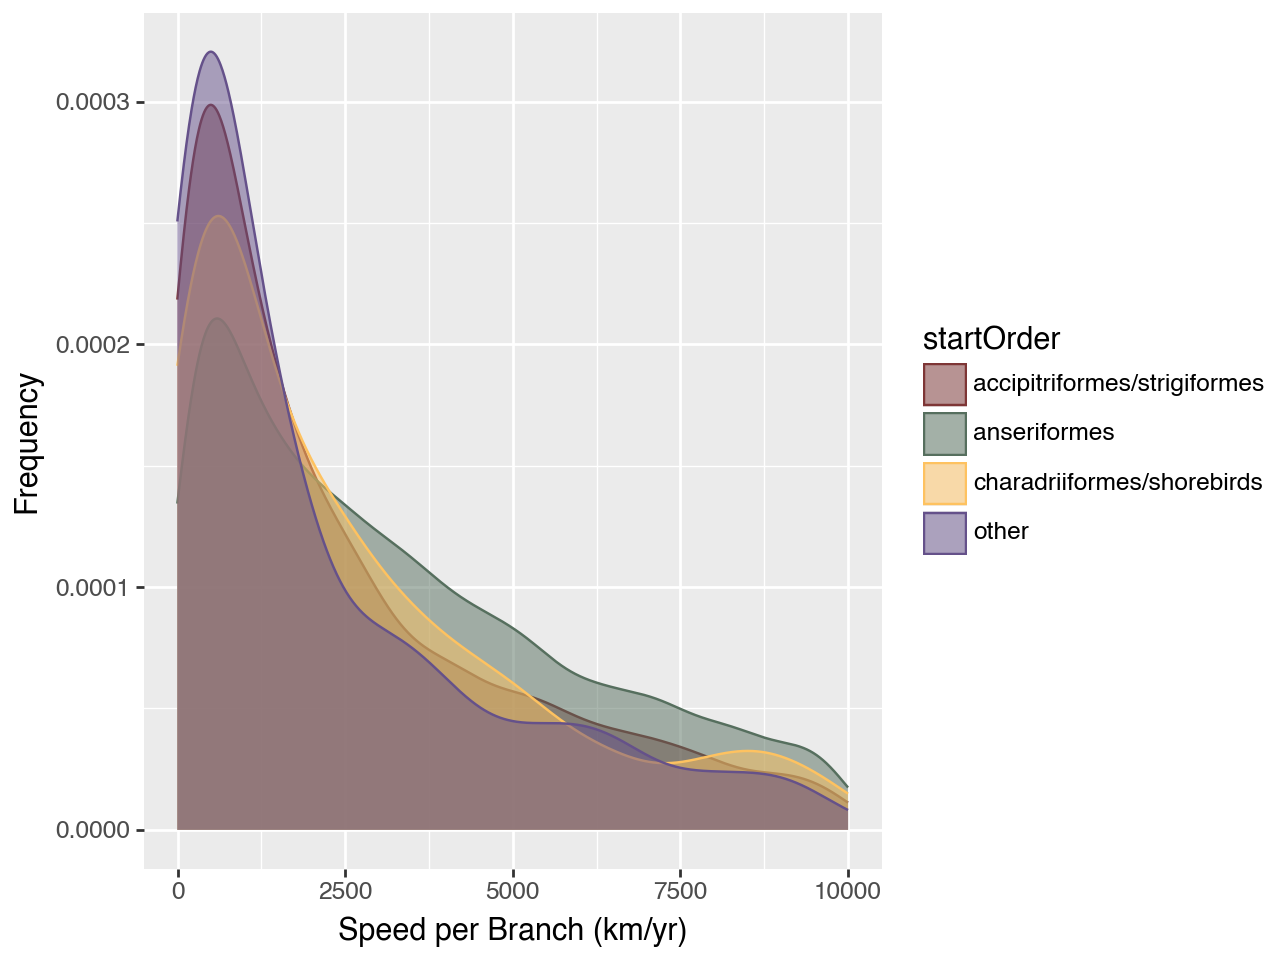

In [60]:
# Plot 11, 12, 13, 14, 15, 16, 17: applicable if you have host designations integrated into the csv

host_colors = {"accipitriformes/strigiformes":"#7E3636",
               "anseriformes":"#566F5E",
               "charadriiformes/shorebirds":"#FEC260",
               "other":"#65518A"
              }

start_hosts = (
    ggplot(MCCDATA, aes(x = "startOrder", fill = "startOrder"))
    + geom_col(stat = "count")
    + scale_fill_manual(values=host_colors)
    + theme(axis_text_x=element_text(rotation=30, hjust=1))
    + labs(x = "Starting Node - Host Order", y = "Frequency")
)

change_hosts = (
    ggplot(MCCDATA, aes(x = "changeOrder"))
    + geom_col(stat = "count")
    + labs(x = "Change in Host Order", y = "Frequency")
) 

# Distance over time colored by host
dist_over_time_host = (
    ggplot(MCCDATA, aes(x = "endYear", y = "dist_km", color = "startOrder")) 
    + geom_point(alpha=0.5)
    + scale_color_manual(values=host_colors)
    # + scale_y_log10()
#    + facet_wrap("endYear_whole")
    + labs(x = "Time at End Node", y = "Distance per Branch (km)")
)

# Speed over time colored by host
speed_over_time_host = (
    ggplot(MCCDATA, aes(x = "endYear", y = "branchSpeed", color = "startOrder")) 
    + geom_point(alpha=0.5)
   + facet_wrap("endYear_whole")
    + scale_color_manual(values=host_colors)
    + scale_y_log10()
    + labs(x = "Time at End Node", y = "Speed per Branch (km/yr)")
)

# speed_per_host = (
#     ggplot(MCCDATA, aes(x = "startOrder", y = "branchSpeed", color = "startOrder", fill = "startOrder")) 
#     + geom_violin()
#     + scale_fill_manual(values=host_colors)
#     + scale_color_manual(values=host_colors)
#     + ylim(-5, 10000)
#     + labs(x = "Host", y = "Speed per Branch (km/yr)")
#     + theme(axis_text_x=element_text(rotation=45, hjust=1))
# )

speed_per_host = (
    ggplot(MCCDATA, aes(x = "branchSpeed", fill = "startOrder", color = "startOrder"))
    # + geom_area(stat = "count", alpha = 0.3)
    + geom_density(alpha=0.5)
    + scale_fill_manual(values=host_colors)
    + scale_color_manual(values=host_colors)
    + xlim(-5, 10000)
    + labs(x = "Speed per Branch (km/yr)", y = "Frequency")
)

seasonal_scatter_hosts = (
    ggplot(MCCDATA, aes(x = "changeLon", y = "changeLat", color = "startOrder")) 
    + geom_point(alpha = 0.5)
    + scale_color_manual(values=host_colors)
    + facet_grid("endYear_whole ~ season")
    + xlim(-100, 100)
    + ylim(-35, 35)
    + labs(x = "Change in Longitude \n West to East", y = "Change in Latitude \n South to North")
    + theme(figure_size = (10, 5))
)

# Heat map of what each change in order goes from and to
MCCDATA_hostchanges = MCCDATA[MCCDATA["changeOrder"] == "yes"].groupby(['startOrder', 'endOrder']).size().reset_index(name='freq')
from_to_host = (
    ggplot(MCCDATA_hostchanges, aes(x = "startOrder", y = "endOrder", fill = "freq")) 
    + geom_tile() 
    + labs(title = "Transmission Between Orders", x = "From", y = "To")
    + theme_minimal()
    + theme(axis_text_x=element_text(rotation=45, hjust=1))
)

#start_hosts.show()
#change_hosts.show()
#dist_over_time_host.show()
#speed_over_time_host.show()
speed_per_host.show()
#seasonal_scatter_hosts.show()
#from_to_host.show()

In [64]:
print(MCCDATA["branchSpeed"].min())
print(MCCDATA["dist_km"].min())
print(MCCDATA["changeYear"].min())

-2309209.7019116348
0.1588040308979866
-0.07173854090592613


In [53]:
# Compute some statistics

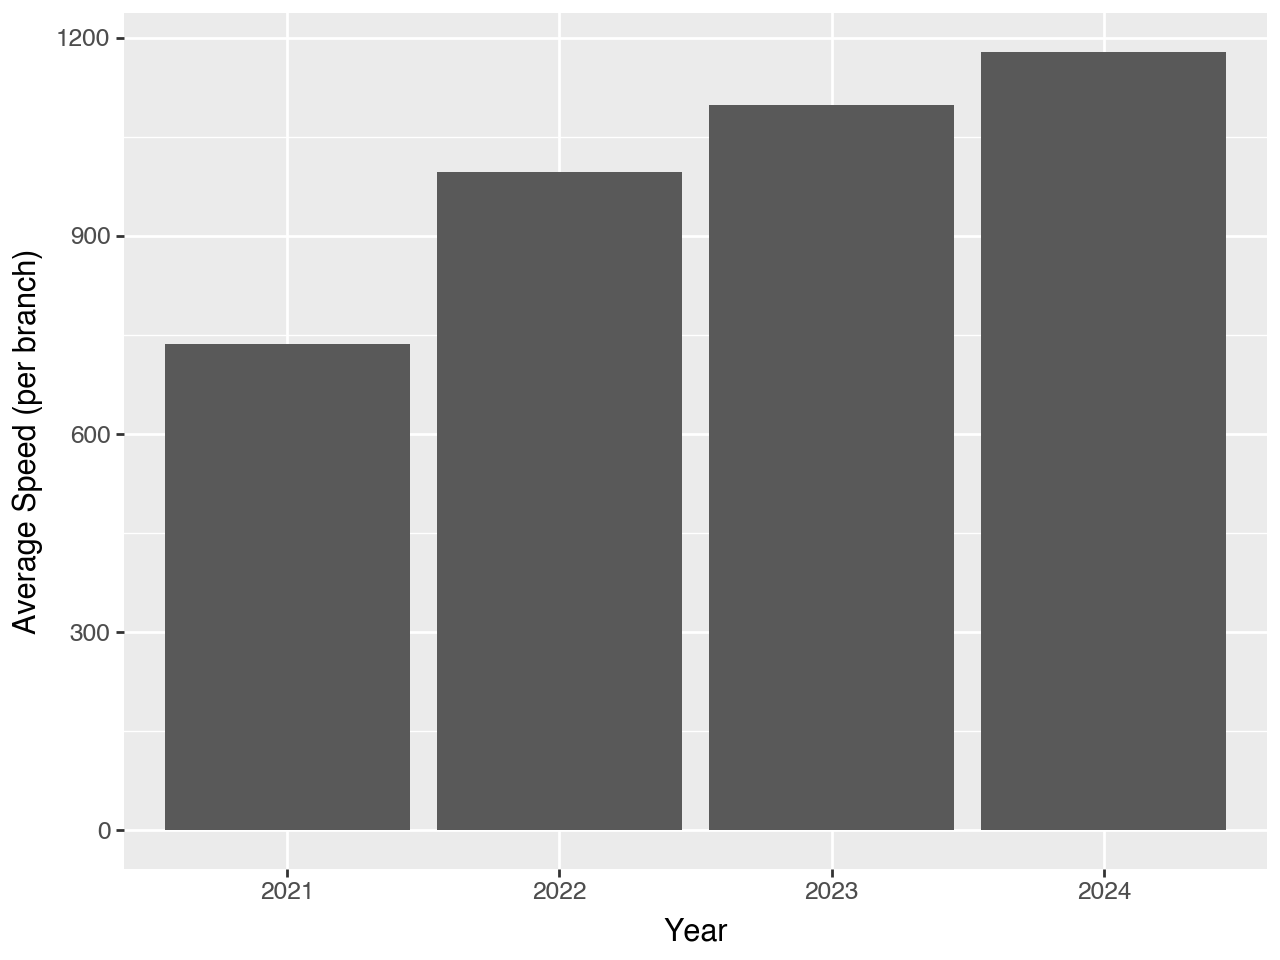

In [75]:
# Statistics per year

stats_by_year_df = pd.DataFrame(["2021", "2022", "2023", "2024"]).rename({0:"year"}, axis = 1)

stats_by_year_df["total_speedperbranch"] = MCCDATA.groupby('endYear_whole')['branchSpeed'].sum().to_list()
stats_by_year_df["mean_speedperbranch"] = MCCDATA.groupby('endYear_whole')['branchSpeed'].mean().to_list()
stats_by_year_df["median_speedperbranch"] = MCCDATA.groupby('endYear_whole')['branchSpeed'].median().to_list()
stats_by_year_df["sd_speedperbranch"] = MCCDATA.groupby('endYear_whole')['branchSpeed'].std().to_list()

stats_by_year_df.head()

stats_by_year_plot = (
    ggplot(stats_by_year_df, aes(x = "year", y = "mean_speedperbranch"))
    + geom_col()
    + labs(x = "Year", y = "Average Speed (per branch)")
)

stats_by_year_plot.show()

/Users/claramal/miniconda3/lib/python3.11/site-packages/plotnine/layer.py:344: PlotnineWarning: position_stack : Removed 1 rows containing missing values.


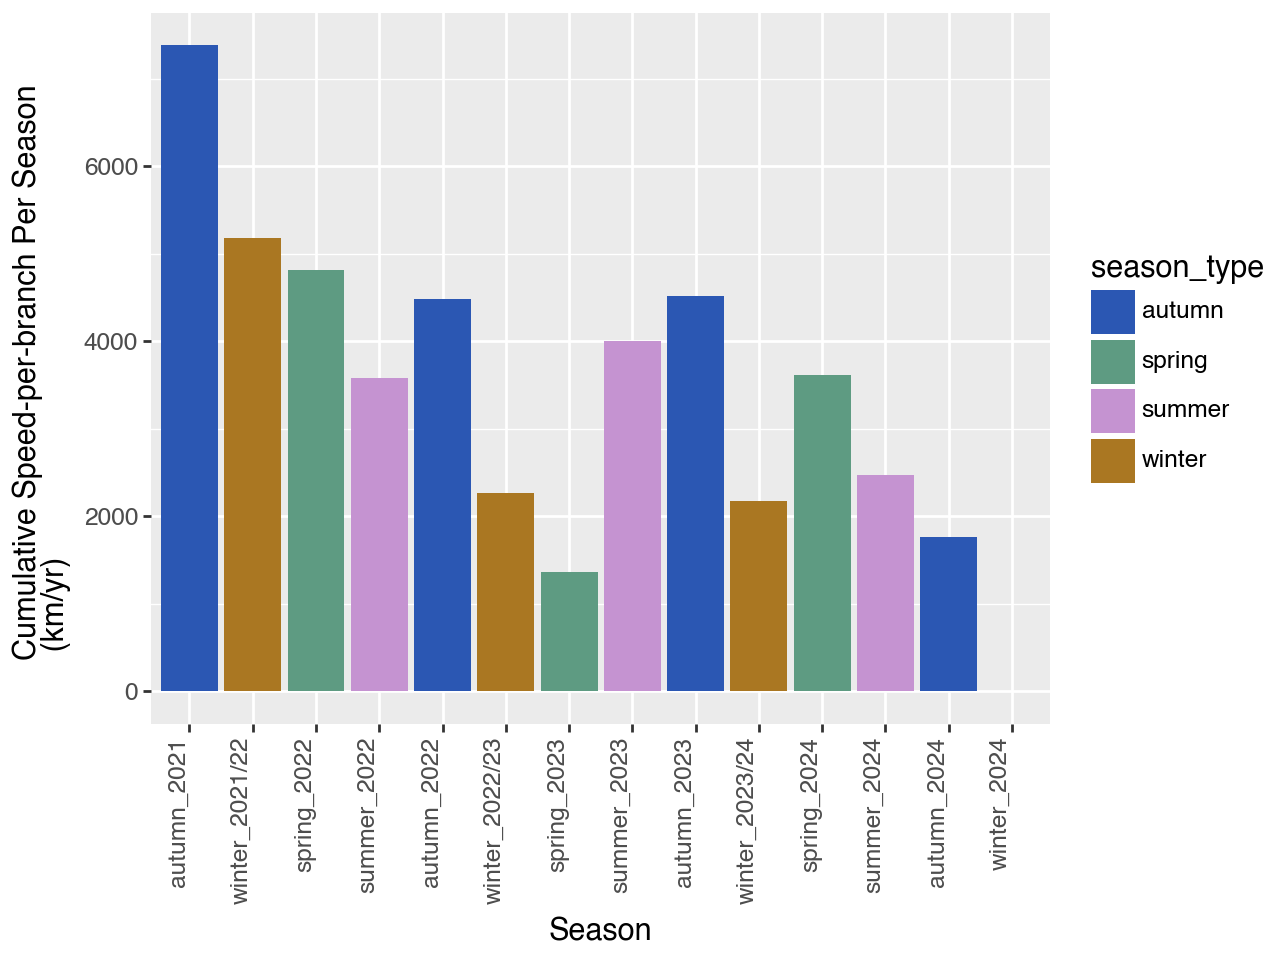

In [51]:
# CUMULATIVE speed per season

# print(season_year_order)

# seasons = season_year_order

summary_list = []

for season in season_year_order:

    season_df = MCCDATA[MCCDATA["season_year"] == season]
    
    # Add the distance
    cumulative_dist = season_df["dist_km"].sum()

    # Compute elapsed time
    #time = season_df["endYear"].max() - season_df["endYear"].min()
    time = season_df["changeYear"].sum()

    number_branches = len(season_df)

    # Compute cumulative speed
    cumulative_speed = cumulative_dist / time if time != 0 else None
    
    season_type = season.split("_")[0]

    summary_list.append({
        "season": season,
        "cumulative_dist": cumulative_dist,
        "time": time,
        "cumulative_speed": cumulative_speed,
        "season_type": season_type
    })

cumulative_speed_df = pd.DataFrame(summary_list)

cumulative_speed_df["season"] = pd.Categorical(cumulative_speed_df["season"], categories=season_year_order, ordered=True)

cumulative_speed_plot = (
    ggplot(cumulative_speed_df, aes(x = "season", y = "cumulative_speed", fill = "season_type"))
    + geom_col()
    + labs(x = "Season", y = "Cumulative Speed-per-branch Per Season \n (km/yr)")
    + scale_fill_manual(values=season_colors)
    + theme(axis_text_x=element_text(rotation=90, hjust=1))
)
cumulative_speed_plot.show()

In [73]:
# Statistics per season

#mcc_seas_mon["season_year"] = mcc_seas_mon["endYear_whole"].astype(str) + "_" + mcc_seas_mon["season"].astype(str) # This is totally wrong
# If I make season_year this way, it considers December 2022 in the same season as January 2022, and they are NOT

stats_by_season_df = pd.DataFrame(["autumn", "winter", "spring", "summer"]).rename({0:"season"}, axis = 1)

stats_by_season_df["total_changeLat"] = MCCDATA.groupby('season')['changeLat'].sum().to_list()
stats_by_season_df["avg_changeLat"] = MCCDATA.groupby('season')['changeLat'].mean().to_list()
stats_by_season_df["total_changeLon"] = MCCDATA.groupby('season')['changeLon'].sum().to_list()
stats_by_season_df["avg_changeLon"] = MCCDATA.groupby('season')['changeLon'].mean().to_list()

print(stats_by_season_df) # Table view

   season  total_changeLat  avg_changeLat  total_changeLon  avg_changeLon
0  autumn      -343.139124      -0.117032         9.915012       0.003382
1  winter      -210.229821      -0.072971       209.012496       0.072549
2  spring      1623.138467       0.427817     -1427.056163      -0.376135
3  summer       191.109756       0.079069      -807.137267      -0.333942


/var/folders/8z/j5vh6t990rj40lqqxtsr69z00000gp/T/ipykernel_36335/237869235.py:8: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
/var/folders/8z/j5vh6t990rj40lqqxtsr69z00000gp/T/ipykernel_36335/237869235.py:9: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
/var/folders/8z/j5vh6t990rj40lqqxtsr69z00000gp/T/ipykernel_36335/237869235.py:10: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
/var/folders/8z/j5vh6t990rj40lqqxtsr69z00000gp/T

In [29]:
# T test - Change in Latitude and Longitude

# First: make a list of the change in latitude and longitude by season
changeLat_autumn = mcc_seas_mon[mcc_seas_mon["season"] == "autumn"]["changeLat"].to_list()
changeLat_winter = mcc_seas_mon[mcc_seas_mon["season"] == "winter"]["changeLat"].to_list()
changeLat_summer = mcc_seas_mon[mcc_seas_mon["season"] == "summer"]["changeLat"].to_list()
changeLat_spring = mcc_seas_mon[mcc_seas_mon["season"] == "spring"]["changeLat"].to_list()

changeLon_autumn = mcc_seas_mon[mcc_seas_mon["season"] == "autumn"]["changeLon"].to_list()
changeLon_winter = mcc_seas_mon[mcc_seas_mon["season"] == "winter"]["changeLon"].to_list()
changeLon_summer = mcc_seas_mon[mcc_seas_mon["season"] == "summer"]["changeLon"].to_list()
changeLon_spring = mcc_seas_mon[mcc_seas_mon["season"] == "spring"]["changeLon"].to_list()

# Set up a dataframe
change_ttest = pd.DataFrame(["Autumn-Winter", "Autumn-Spring", "Autumn-Summer", 
                                "Winter-Spring", "Winter-Summer",
                                "Spring-Summer"]).rename({0:"Compared"}, axis = 1)

# Calculate t-statistics and p-values
t_statistic_lat_AutWin, p_value_lat_AutWin = ttest_ind(changeLat_autumn, changeLat_winter) # should check and make sure this is a commonly used function
t_statistic_lat_AutSpr, p_value_lat_AutSpr = ttest_ind(changeLat_autumn, changeLat_spring)
t_statistic_lat_AutSum, p_value_lat_AutSum = ttest_ind(changeLat_autumn, changeLat_summer)
t_statistic_lat_WinSpr, p_value_lat_WinSpr = ttest_ind(changeLat_winter, changeLat_spring)
t_statistic_lat_WinSum, p_value_lat_WinSum = ttest_ind(changeLat_winter, changeLat_summer)
t_statistic_lat_SprSum, p_value_lat_SprSum = ttest_ind(changeLat_spring, changeLat_summer)

t_statistic_lon_AutWin, p_value_lon_AutWin = ttest_ind(changeLon_autumn, changeLon_winter) 
t_statistic_lon_AutSpr, p_value_lon_AutSpr = ttest_ind(changeLon_autumn, changeLon_spring)
t_statistic_lon_AutSum, p_value_lon_AutSum = ttest_ind(changeLon_autumn, changeLon_summer)
t_statistic_lon_WinSpr, p_value_lon_WinSpr = ttest_ind(changeLon_winter, changeLon_spring)
t_statistic_lon_WinSum, p_value_lon_WinSum = ttest_ind(changeLon_winter, changeLon_summer)
t_statistic_lon_SprSum, p_value_lon_SprSum = ttest_ind(changeLon_spring, changeLon_summer)

# Add values to columns
change_ttest.loc[change_ttest["Compared"] == "Autumn-Winter", "T Statistic (Latitude)"] = t_statistic_lat_AutWin
change_ttest.loc[change_ttest["Compared"] == "Autumn-Winter", "P Value (Latitude)"] = p_value_lat_AutWin
change_ttest.loc[change_ttest["Compared"] == "Autumn-Spring", "T Statistic (Latitude)"] = t_statistic_lat_AutSpr
change_ttest.loc[change_ttest["Compared"] == "Autumn-Spring", "P Value (Latitude)"] = p_value_lat_AutSpr
change_ttest.loc[change_ttest["Compared"] == "Autumn-Summer", "T Statistic (Latitude)"] = t_statistic_lat_AutSum
change_ttest.loc[change_ttest["Compared"] == "Autumn-Summer", "P Value (Latitude)"] = p_value_lat_AutSum
change_ttest.loc[change_ttest["Compared"] == "Winter-Spring", "T Statistic (Latitude)"] = t_statistic_lat_WinSpr
change_ttest.loc[change_ttest["Compared"] == "Winter-Spring", "P Value (Latitude)"] = p_value_lat_WinSpr
change_ttest.loc[change_ttest["Compared"] == "Winter-Summer", "T Statistic (Latitude)"] = t_statistic_lat_WinSum
change_ttest.loc[change_ttest["Compared"] == "Winter-Summer", "P Value (Latitude)"] = p_value_lat_WinSum
change_ttest.loc[change_ttest["Compared"] == "Spring-Summer", "T Statistic (Latitude)"] = t_statistic_lat_SprSum
change_ttest.loc[change_ttest["Compared"] == "Spring-Summer", "P Value (Latitude)"] = p_value_lat_SprSum

change_ttest.loc[change_ttest["Compared"] == "Autumn-Winter", "T Statistic (Longitude)"] = t_statistic_lon_AutWin
change_ttest.loc[change_ttest["Compared"] == "Autumn-Winter", "P Value (Longitude)"] = p_value_lon_AutWin
change_ttest.loc[change_ttest["Compared"] == "Autumn-Spring", "T Statistic (Longitude)"] = t_statistic_lon_AutSpr
change_ttest.loc[change_ttest["Compared"] == "Autumn-Spring", "P Value (Longitude)"] = p_value_lon_AutSpr
change_ttest.loc[change_ttest["Compared"] == "Autumn-Summer", "T Statistic (Longitude)"] = t_statistic_lon_AutSum
change_ttest.loc[change_ttest["Compared"] == "Autumn-Summer", "P Value (Longitude)"] = p_value_lon_AutSum
change_ttest.loc[change_ttest["Compared"] == "Winter-Spring", "T Statistic (Longitude)"] = t_statistic_lon_WinSpr
change_ttest.loc[change_ttest["Compared"] == "Winter-Spring", "P Value (Longitude)"] = p_value_lon_WinSpr
change_ttest.loc[change_ttest["Compared"] == "Winter-Summer", "T Statistic (Longitude)"] = t_statistic_lon_WinSum
change_ttest.loc[change_ttest["Compared"] == "Winter-Summer", "P Value (Longitude)"] = p_value_lon_WinSum
change_ttest.loc[change_ttest["Compared"] == "Spring-Summer", "T Statistic (Longitude)"] = t_statistic_lon_SprSum
change_ttest.loc[change_ttest["Compared"] == "Spring-Summer", "P Value (Longitude)"] = p_value_lon_SprSum

print(change_ttest)

        Compared  T Statistic (Latitude)  P Value (Latitude)  \
0  Autumn-Winter               -0.522229        6.015306e-01   
1  Autumn-Spring               -7.000575        2.796096e-12   
2  Autumn-Summer               -2.234039        2.552167e-02   
3  Winter-Spring               -8.309147        1.156884e-16   
4  Winter-Summer               -2.445153        1.451142e-02   
5  Spring-Summer                5.712669        1.163744e-08   

   T Statistic (Longitude)  P Value (Longitude)  
0                -0.470874             0.637748  
1                 2.360780             0.018265  
2                 2.193133             0.028341  
3                 3.263116             0.001107  
4                 3.640395             0.000275  
5                -0.291557             0.770635  


In [54]:
# T test - Average Latitude

avgLat_autumn = mcc_seas_mon[mcc_seas_mon["season"] == "autumn"].groupby("endYear_whole")["changeLat"].mean().to_list()
avgLat_winter = mcc_seas_mon[mcc_seas_mon["season"] == "winter"].groupby("endYear_whole")["changeLat"].mean().to_list()
avgLat_summer = mcc_seas_mon[mcc_seas_mon["season"] == "summer"].groupby("endYear_whole")["changeLat"].mean().to_list()
avgLat_spring = mcc_seas_mon[mcc_seas_mon["season"] == "spring"].groupby("endYear_whole")["changeLat"].mean().to_list()

avgLat_ttest = pd.DataFrame(["Autumn-Winter", "Autumn-Spring", "Autumn-Summer", 
                                "Winter-Spring", "Winter-Summer",
                                "Spring-Summer"]).rename({0:"Compared"}, axis = 1)

t_statistic_avgLat_AutWin, p_value_avgLat_AutWin = ttest_ind(avgLat_autumn, avgLat_winter) # should check and make sure this is a commonly used function
t_statistic_avgLat_AutSpr, p_value_avgLat_AutSpr = ttest_ind(avgLat_autumn, avgLat_spring)
t_statistic_avgLat_AutSum, p_value_avgLat_AutSum = ttest_ind(avgLat_autumn, avgLat_summer)
t_statistic_avgLat_WinSpr, p_value_avgLat_WinSpr = ttest_ind(avgLat_winter, avgLat_spring)
t_statistic_avgLat_WinSum, p_value_avgLat_WinSum = ttest_ind(avgLat_winter, avgLat_summer)
t_statistic_avgLat_SprSum, p_value_avgLat_SprSum = ttest_ind(avgLat_spring, avgLat_summer)

avgLat_ttest.loc[avgLat_ttest["Compared"] == "Autumn-Winter", "T Statistic"] = t_statistic_avgLat_AutWin
avgLat_ttest.loc[avgLat_ttest["Compared"] == "Autumn-Winter", "P Value"] = p_value_avgLat_AutWin
avgLat_ttest.loc[avgLat_ttest["Compared"] == "Autumn-Spring", "T Statistic"] = t_statistic_avgLat_AutSpr
avgLat_ttest.loc[avgLat_ttest["Compared"] == "Autumn-Spring", "P Value"] = p_value_avgLat_AutSpr
avgLat_ttest.loc[avgLat_ttest["Compared"] == "Autumn-Summer", "T Statistic"] = t_statistic_avgLat_AutSum
avgLat_ttest.loc[avgLat_ttest["Compared"] == "Autumn-Summer", "P Value"] = p_value_avgLat_AutSum
avgLat_ttest.loc[avgLat_ttest["Compared"] == "Winter-Spring", "T Statistic"] = t_statistic_avgLat_WinSpr
avgLat_ttest.loc[avgLat_ttest["Compared"] == "Winter-Spring", "P Value"] = p_value_avgLat_WinSpr
avgLat_ttest.loc[avgLat_ttest["Compared"] == "Winter-Summer", "T Statistic"] = t_statistic_avgLat_WinSum
avgLat_ttest.loc[avgLat_ttest["Compared"] == "Winter-Summer", "P Value"] = p_value_avgLat_WinSum
avgLat_ttest.loc[avgLat_ttest["Compared"] == "Spring-Summer", "T Statistic"] = t_statistic_avgLat_SprSum
avgLat_ttest.loc[avgLat_ttest["Compared"] == "Spring-Summer", "P Value"] = p_value_avgLat_SprSum

print(avgLat_ttest)

        Compared  T Statistic   P Value
0  Autumn-Winter     0.756135  0.478194
1  Autumn-Spring    -1.912072  0.114083
2  Autumn-Summer    -0.935915  0.392282
3  Winter-Spring    -3.308645  0.021272
4  Winter-Summer    -2.068790  0.093383
5  Spring-Summer     0.947540  0.397018


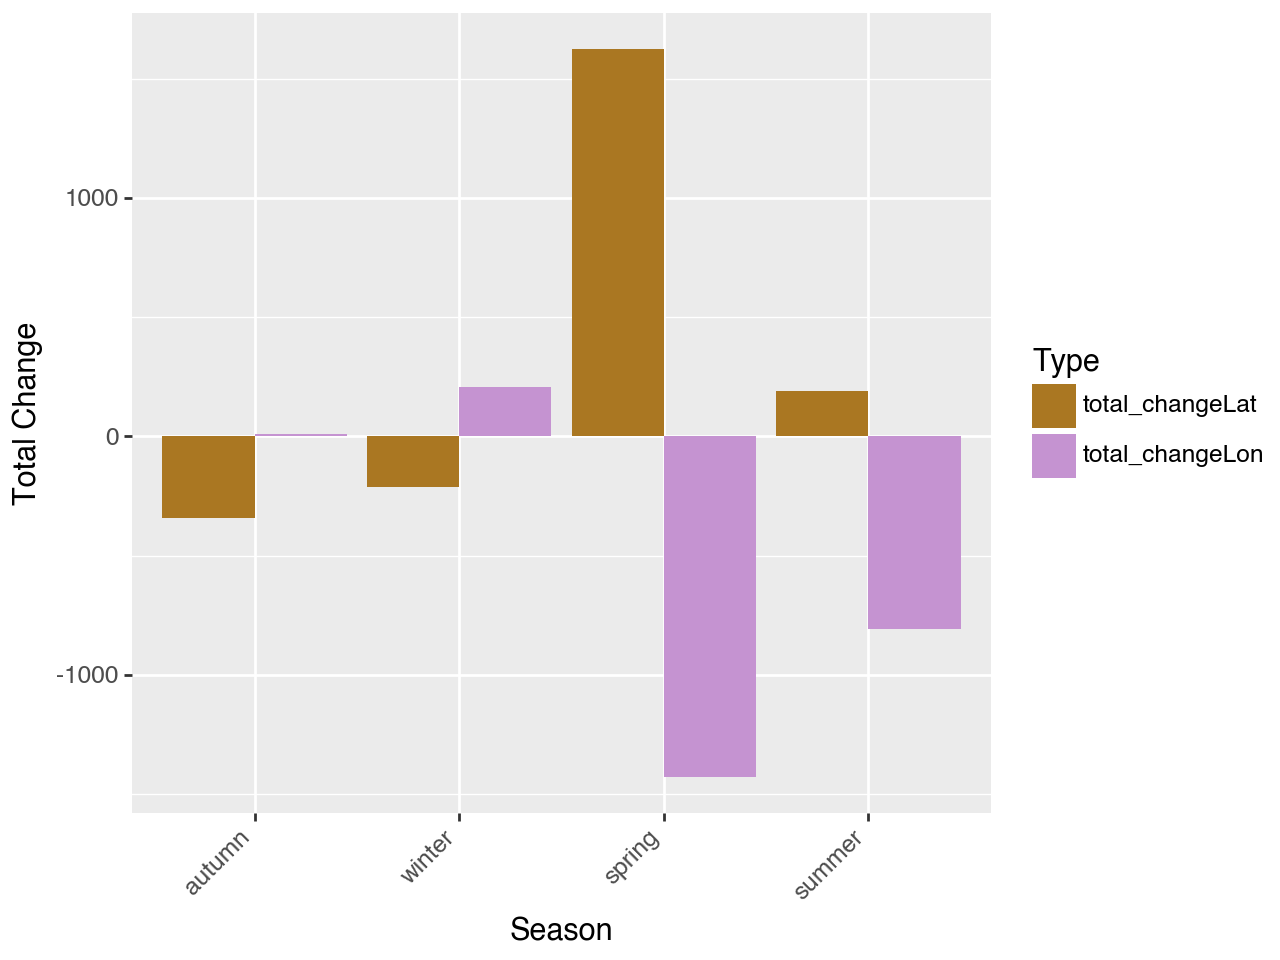

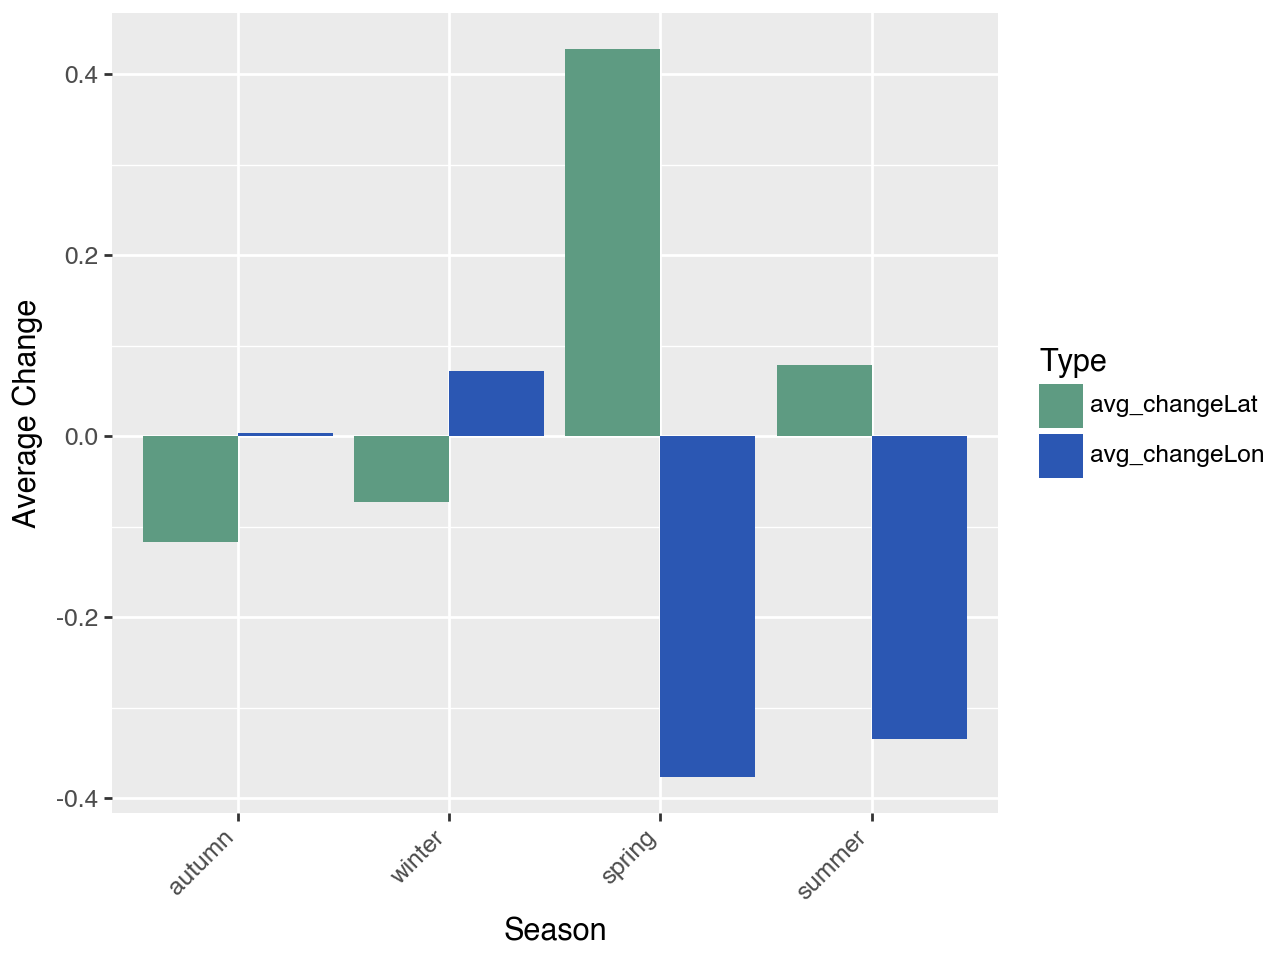

In [74]:
# Plot 7: change in lat and long per season

# Chat GPT says I need to reshape by df first
stats_by_season_long = stats_by_season_df.melt(
    id_vars=['season'], 
    value_vars=['total_changeLat', 'avg_changeLat', 'total_changeLon', 'avg_changeLon'],
    var_name='change_type',
    value_name='value'
)

season_order = ["autumn", "winter", "spring", "summer"]
stats_by_season_long["season"] = pd.Categorical(stats_by_season_long["season"], categories=season_order, ordered=True)

# Filter for averages
filtered_total = stats_by_season_long[stats_by_season_long["change_type"].isin(["total_changeLat", "total_changeLon"])]

# Filter for totals
filtered_avg = stats_by_season_long[stats_by_season_long["change_type"].isin(["avg_changeLat", "avg_changeLon"])]

total_change_per_season = (
    ggplot(filtered_total) 
    + geom_col(aes(x = "season", y='value', fill='change_type'), position='dodge')
    + labs(x = "Season", y = "Total Change", fill = "Type")
    + scale_fill_manual(values={'total_changeLat': '#AA7722','total_changeLon': '#C593D1'})
    + theme(axis_text_x=element_text(rotation=45, hjust=1))
)

avg_change_per_season = (
    ggplot(filtered_avg) 
    + geom_col(aes(x = "season", y='value', fill='change_type'), position='dodge')
    + labs(x = "Season", y = "Average Change", fill = "Type")
    + scale_fill_manual(values={'avg_changeLat': '#5E9B82', 'avg_changeLon': '#2B57B3'})
    + theme(axis_text_x=element_text(rotation=45, hjust=1))
)

total_change_per_season.show()
avg_change_per_season.show()

In [66]:
# Statistics per month_year

stats_by_month_df = pd.DataFrame(["2021_september", "2021_october","2021_november","2021_december",
                                  "2022_january", "2022_february", "2022_march", "2022_april", "2022_may", "2022_june",
                                  "2022_july", "2022_august", "2022_september", "2022_october", "2022_november", "2022_december",
                                  "2023_january", "2023_february", "2023_march", "2023_april", "2023_may", "2023_june",
                                  "2023_july", "2023_august", "2023_september", "2023_october", "2023_november", "2023_december",
                                  "2024_january", "2024_february", "2024_march", "2024_april", "2024_may", "2024_june",
                                  "2024_july", "2024_august", "2024_september", "2024_october", "2024_november", "2024_december"]).rename({0:"month"}, axis = 1)

stats_by_month_df["avg_startLat"] = mcc_seas_mon.groupby('month_year')['startLat'].mean().to_list()
stats_by_month_df["avg_startLon"] = mcc_seas_mon.groupby('month_year')['startLon'].mean().to_list()
stats_by_month_df["avg_endLat"] = mcc_seas_mon.groupby('month_year')['endLat'].mean().to_list()
stats_by_month_df["avg_endLon"] = mcc_seas_mon.groupby('month_year')['endLon'].mean().to_list()

#print(stats_by_month_df) # Table view